# PI AutoDecomp : Séparation de sources sonores

## I - Introduction

### 1 - Rappel du sujet

La séparation des diverses composantes d’un signal musical à partir d’un enregistrement monophonique représente un défi de recherche qui attire l’attention depuis de nombreuses années. Ce sujet trouve son application dans divers domaines, notamment la transcription musicale automatique, l’identification des instruments musicaux, l’analyse de mélodies ou l’analyse de scènes sonores. La difficulté de ce problème est accentuée par plusieurs facteurs, comme la complexité des sources musicales dans les mélanges de Bachs, les variations des conditions d’enregistrement, le bruit ambiant, ainsi que les effets numériques utilisés lors
des enregistrements audio.

### 2 - Comment le résoudre ?

Notre but ici est donc de comprendre comment séparer efficacement un signal en différentes sources afin d'isoler chaque composant. Pour ce faire, nous nous sommes aidés de la consigne suivante :

"Pour transformer le signal audio (Fig. 1) en données exploitables, on pourra se focaliser sur la transformée de Fourier et ses dérivées utilisées sur un signal numérique fini. Cela permettra d’obtenir un spectrogramme (Fig. 2) sous forme d’une matrice, que l’on cherchera alors à factoriser.

La séparation de sources consiste à décomposer le spectrogramme en deux éléments : un premier élément contenant les sources qui composent le signal, ainsi qu’un deuxième élément codant les activations de ces sources dans le temps (voir Fig. 3).

Cette décomposition matricielle peut se faire grâce aux méthodes de factorisation en matrices non-négatives (NMF). La NMF est un processus de décomposition qui modélise les données observées à travers un nombre restreint de composants sources significatifs. Dans ce projet, nous envisageons d’exploiter cette méthode pour parvenir à une séparation efficace des sources musicales. Cette décomposition permettra de reconstruire les signaux sources comme dans la Fig. 4."

Cela nous aide grandement puisqu'en faisant quelques recherches rapides, nous nous rendons compte qu'il va nous falloir plusieurs outils :
- la STFT (Short Time Fourier Transform) afin d'obtenir le spectrogramme sous forme matricielle que nous pourrons utiliser
- La NMF (Non-negative Matrix Factorization) afin de décomposer notre matrice obtenue en deux matrices :
  - La matrice D qui correspond aux différents sources
  - La matrice A qui correspond à l'activation de sources
- Faire l'ISTFT (Inverse Short Time Fourier Transform) afin de récupérer la liste des différentes sources

Ainsi, nous aurons récupéré la liste des différentes sources sonores correspondantes aux composants du signal sonore de base.

### 3 - Mise en place du projet

Avant de commencer les recherches, il est nécessaire de commencer avec les bonnes bases pour que le projet se déroule correctement.

Ainsi, nous utilisons le langage **`Python`** dû à ses nombreuses librairies permettant de facilement manipuler des opérations matricielles. De plus, afin de se répartir correctement le travail, nous utilisons la plateforme **`GitLab`**. De ce fait, cela nous aidera à travailler en cohésion sur différents fichiers facilement tout en travaillant sur les compétences de base d'un ingénieur actuel, à savoir la connaissance de l'outil *Git*.

Dans le but d'avoir un travail fluide et clair, nous avons décidé de travailler sur une structure de travail modulaire où nous utilisons différents fichiers *.py* dans *src/* où nous pourrons travailler sur nos programmes respectifs tout en étant en capacité de se repérer sur l'emplacement de chaque fonction. Malgré cette mise en place modulaire, les imports avec Python nous obligeront à redéfinir nos fonctions dans les Notebook Jupyter. Cela n'en reste pas moins une bonne pratique qui nous sera utile dans le temps (il nous suffit de travailler sur le fichier source et lorsque la fonction doit être remplacée, un simple copié-collé suffira).

L'arborescence du projet est expliqué clairement dans le fichier **`README.md`** qui explique comment le projet est mis en place et comment une nouvelle personne peut vite comprendre comment il est structuré sans avoir à le décoder par l'exploration.

Enfin, avant de commencer, nous savons qu'il est nécessaire d'utiliser différentes librairies python dans notre projet (Numpy, Scipy, ...). Ainsi, afin de travailler correctement, il nous faut installer un __*environnement*__ de travail. Nous avons donc identifié les différentes librairies utilisées au fil du projet puis les avons ajoutées dans un fichier **`requirements.txt`** qui facilitera leur installation. La façon dont l'environnement est mis en place est détaillée dans le *README.md*

## II - Premiers pas
### 1. Calcul de la STFT avec une fenêtre de Hann

Dans cette partie du projet, nous avons appliqué une STFT (Short-Time Fourier Transform) aux signaux audios afin d’analyser leur contenu fréquentiel en fonction du temps.
Contrairement à la FFT classique, la STFT permet d’observer l’évolution des fréquences au cours du signal, ce qui est essentiel pour l’étude :<br>
- d’un extrait de piano<br>
- d’un enregistrement de Bach <br>
- d’un extrait animal (principalement un cheval mais aussi un vérin ainsi que des humains)

### 2. Détermination automatique des paramètres de la STFT

Afin d’adapter la STFT aux différentes longueurs de signaux utilisés dans le projet, nous avons implémenté une fonction permettant de calculer automatiquement les deux paramètres essentiels :<br>
- nperseg : taille de la fenêtre d’analyse<br>
- noverlap : pourcentage de recouvrement entre fenêtres

### 3. Analyse temporelle-fréquentielle avec fenêtre gaussienne

Après avoir réalisé une STFT à l’aide d’une fenêtre de Hann, nous avons implémenté une seconde méthode basée sur l’utilisation d’une fenêtre gaussienne.<br>
Le but était de comparer l’influence du choix de la fenêtre sur :
la résolution temporelle,la résolution fréquentielle,l’apparence du spectrogramme.<br>

La fenêtre gaussienne est souvent utilisée en traitement du signal car elle minimise l’incertitude temps–fréquence en respectant une forme proche de la distribution gaussienne idéale

### 4. Décomposition du spectrogramme par la méthode NMF (Gauss–Seidel)

Après avoir obtenu les différents spectrogrammes (Hann et Gauss), nous avons cherché à analyser les composantes internes du signal en utilisant une factorisation en matrices non-négatives (NMF).
Cette méthode permet de décomposer un spectrogramme en plusieurs bases fréquentielles et leurs activations temporelles.

Cela permet de :<br>
- identifier différents instruments dans un enregistrement de Bach<br>
- isoler des motifs fréquentiels récurrents<br>
- réduire la dimension du signal<br>
- séparer des sources audio simples.

## III - Comprendre le déroulé interne

## 1. Réalisation de la stft

##### Import des bibliothèques et chargement des fichiers audio
Afin de mener à bien ce projet, il est nécessaire d’importer les bibliothèques Python utilisées et charger les différents fichiers audio fournis pour le projet.

In [1]:
# Import des bibliothèques
from scipy.io import wavfile                                                                                                            
import scipy as sc
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

In [2]:
# Chargement des fichiers audio
freq_piano, extrait_piano = wavfile.read("../data/piano_mix.wav")
freq_anim, extrait_anim = wavfile.read("../data/horse_and_chat.wav")
freq_bach, extrait_bach = wavfile.read("../data/01-AchGottundHerr.wav")

### 1.1 Analyse temporelle du signal audio avec la Transformée de Fourier 
Afin d’analyser le contenu fréquentiel du signal, nous appliquons une Transformée de Fourier Discrète.
Cette transformation permet de passer du domaine temporel au domaine fréquentiel.

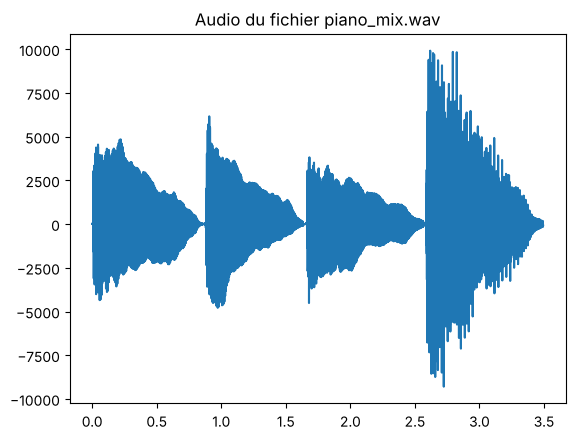

In [3]:
# Reconstruction de l'axe temporel
t_extrait_piano = np.arange(0, len(extrait_piano)/freq_piano, 1/freq_piano)

# Tracé du signal audio
plt.plot(t_extrait_piano, extrait_piano)
plt.title("Audio du fichier piano_mix.wav")
plt.show()

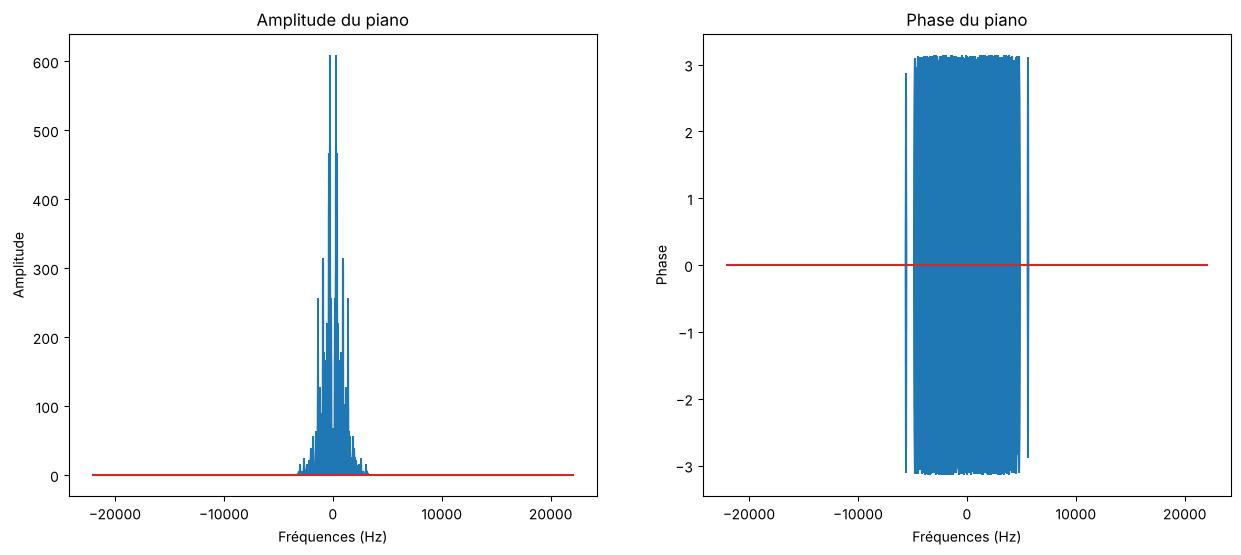

In [4]:
# On réalise la Transformée de Fourier du signal audio
n = len(extrait_piano)
TF_piano = np.fft.fft(extrait_piano)
freq_TF_piano = np.fft.fftfreq(n, 1/freq_piano)

amp_piano = np.abs(TF_piano)
# correction de l'amplitude
amp_piano = amp_piano * 2 / n

phase_piano = np.angle(TF_piano)
# correction de la phase
phase_piano[amp_piano<0.01*phase_piano.max()] = 0

# Affichage de l'amplitude et la phase
plt.subplots(1,2,figsize=(15,6))
plt.subplot(121)
plt.stem(freq_TF_piano, amp_piano, markerfmt=" ")
plt.title("Amplitude du piano")
plt.xlabel("Fréquences (Hz)")
plt.ylabel("Amplitude")
plt.subplot(122)
plt.stem(freq_TF_piano, phase_piano, markerfmt=" ")
plt.title("Phase du piano")
plt.xlabel("Fréquences (Hz)")
plt.ylabel("Phase")
plt.show()

Comme nous pouvons le voir sur ces schémas, la Transformée de Fourier ne permet pas d’obtenir d’informations au niveau temporel.

Elle permet uniquement de savoir quelles fréquences sont présentes dans le signal, mais pas quand elles apparaissent ni comment elles évoluent au cours du temps. Elle ne convient donc pas à la résolution de notre problème.

### 1.2 Analyse temps-fréquence avec la STFT

Afin de résoudre notre problème, nous utiliserons donc la STFT (Short-Time Fourier Transform).

Cette méthode consiste à découper le signal audio en segments temporels de courte durée à l’aide d’une fenêtre glissante, puis à appliquer une Transformée de Fourier sur chacun de ces segments.

Avant toute chose, il est important de savoir que la STFT nécessite des paramètres d’entrée qu’il faut déterminer au préalable. C’est pourquoi nous avons réalisé une fonction permettant de calculer automatiquement ces paramètres.

In [5]:
# Fonction pour calculer nperseg et noverlap pour la STFT
def calculate_stft_params(signal_data, fs):
    # longueur du signal en échantillons
    N = len(signal_data)

    # fenêtre = 5% du signal
    nperseg = int(0.05 * N)

    # éviter les valeurs trop petites ou trop grandes
    nperseg = max(256, min(nperseg, 8192))

    # arrondir à la puissance de 2 la plus proche
    nperseg = 2**int(np.round(np.log2(nperseg)))

    # recouvrement = moitié de la fenêtre
    noverlap = nperseg // 2

    print(f"[STFT] nperseg = {nperseg}, noverlap = {noverlap}")

    return nperseg, noverlap

D’après nos recherches, il n’existe pas, de manière générale, de « bonne méthode » universelle pour déterminer la taille de la fenêtre. Ce choix repose sur un compromis fondamental temps–fréquence. Une fenêtre courte améliore la résolution temporelle mais dégrade la résolution fréquentielle, tandis qu’une fenêtre longue améliore la résolution fréquentielle mais lisse les variations temporelles.

Dans notre cas, comme il s’agit d’un signal musical, nous avons décidé d’adapter automatiquement la taille de la fenêtre à la longueur du signal en prenant 5 % de celle-ci et en arrondissant le résultat. Concernant le choix du recouvrement (overlap), il nous a été conseillé par le chargé de TD d’utiliser un recouvrement correspondant à 50 % de la taille de la fenêtre.

##### 1.2.1 STFT à l'aide de scipy.signal.stft
Dans un premier temps, nous avons utilisé la STFT fournie par la bibliothèque SciPy, développée par des professionnels et largement documentée.

La fonction présentée précédemment nous permet de déterminer automatiquement les paramètres liés à la taille de la fenêtre d’analyse ainsi qu’au recouvrement (overlap), mais pas le choix du type de fenêtre.

Pour ce paramètre, nous avons donc décidé de comparer deux types de fenêtres mentionnés dans la documentation : la fenêtre de Hann et la fenêtre gaussienne.

In [6]:
# STFT de scipy et avec fenêtre de Hann
def STFT_Hann(x,f):
    # Normalisation
    x = x.astype(float)
    x /= np.max(np.abs(x))

    # Paramètres de STFT et calcul de la stft
    taille,overlap=calculate_stft_params(x,f)
    freq, t, Zxx = sc.signal.stft(x,fs=f,nperseg=taille,noverlap=overlap,window='hann')

    #Valeur absolue
    S = np.abs(Zxx)

    # Passage en dB
    S_db = 20 * np.log10(S + 1e-12)

    return t, freq, S_db, S,Zxx

t_h_piano, STFT_h_piano, piano_h_db, M_piano,Zxx_piano = STFT_Hann(extrait_piano,freq_piano)
t_h_bach, STFT_h_bach, bach_h_db, M_bach,Zxx_bach = STFT_Hann(extrait_bach,freq_bach)
t_h_anim, STFT_h_anim, anim_h_db, M_anim,Zxx_anim = STFT_Hann(extrait_anim,freq_anim)

[STFT] nperseg = 8192, noverlap = 4096


[STFT] nperseg = 8192, noverlap = 4096
[STFT] nperseg = 8192, noverlap = 4096


In [7]:
# STFT de scipy et avec fenêtre gaussienne
def STFT_Gauss(x,f):
    # Normalisation
    x = x.astype(float)
    x /= np.max(np.abs(x))

    # Paramètres de STFT et calcul de la stft
    fenetre = sc.signal.windows.gaussian(50, std=8, sym=True)
    freq, t, Zxx = sc.signal.stft(x,fs=f,nperseg=len(fenetre),noverlap=len(fenetre)//2,window=fenetre)

    #Valeur absolue
    S = np.abs(Zxx)

    # Passage en dB
    S_db = 20 * np.log10(S + 1e-12)

    return t, freq, S_db

t_g_piano, STFT_g_piano, piano_g_db = STFT_Gauss(extrait_piano,freq_piano)

Cela permet d’obtenir une représentation temps–fréquence du signal, appelée spectrogramme, qui conserve à la fois l’information fréquentielle et son évolution dans le temps.

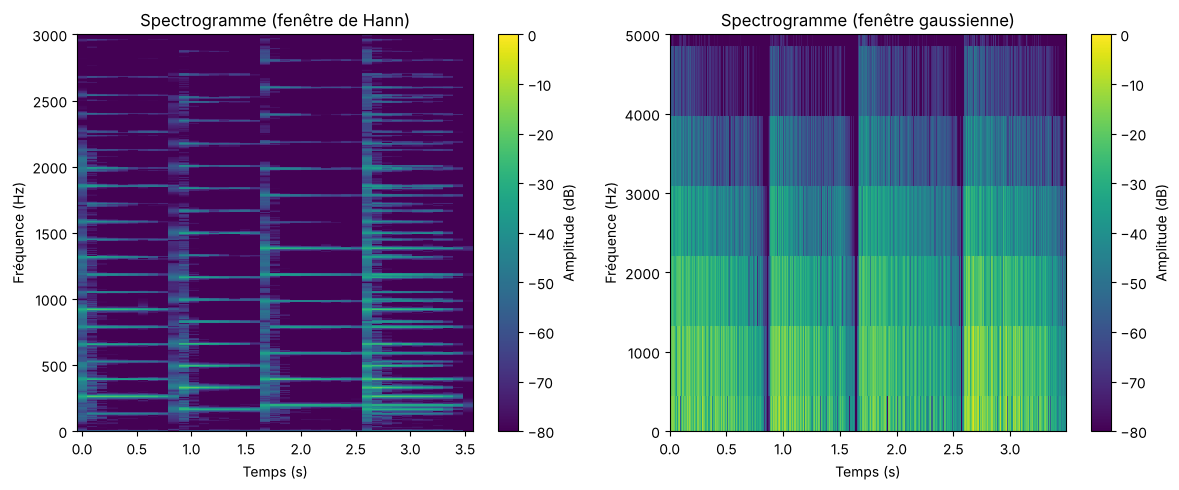

In [8]:
plt.figure(figsize=(12, 5))

# Spectrogramme avec fenêtre de Hann pour le piano
plt.subplot(1, 2, 1)
plt.pcolormesh(t_h_piano, STFT_h_piano, piano_h_db, shading='auto', cmap='viridis')
plt.ylim(0, 3000)
plt.clim(-80, 0)
plt.xlabel("Temps (s)")
plt.ylabel("Fréquence (Hz)")
plt.title("Spectrogramme (fenêtre de Hann)")
cbar1 = plt.colorbar()
cbar1.set_label("Amplitude (dB)")

# Spectrogramme avec fenêtre gaussienne pour le 
plt.subplot(1, 2, 2)
plt.pcolormesh(t_g_piano, STFT_g_piano, piano_g_db, shading='auto', cmap='viridis')
plt.ylim(0, 5000)
plt.clim(-80, 0)
plt.xlabel("Temps (s)")
plt.ylabel("Fréquence (Hz)")
plt.title("Spectrogramme (fenêtre gaussienne)")
cbar2 = plt.colorbar()
cbar2.set_label("Amplitude (dB)")

plt.tight_layout()
plt.show()


En comparant les spectrogrammes, on remarque que celui utilisant la fenêtre de Hann présente de meilleurs résultats que celui obtenu avec la fenêtre gaussienne. Il est plus lisible et correspond davantage à ce qui était présenté dans le sujet.

De plus, d’après la ressource sur l’analyse temps–fréquence, la fenêtre gaussienne est utilisée dans le domaine de l’imagerie médicale. Par ailleurs, selon le document « Décomposition de spectrogrammes musicaux informée par des modèles de synthèse spectrale », une fenêtre de Hann est également utilisée pour la décomposition musicale, ce qui confirme la pertinence de notre choix.

Pourquoi cela ? Il faut s'intéresser à la condition COLA (Constant OverLap Add) qui est $\sum_k w[n-kH]=$ constante avec H la taille du hop (décalage entre deux fenêtres). On rappelle qu'on prend 50% de recouvrement, donc H = n/2 avec n la taille de la fenêtre. On a donc :

$w[n] = \frac{1}{2}(1-\cos(\frac{2\pi n}{n}))$ (formule de la fenêtre de Hann)

donc la somme de deux fenêtres décalées de n/2 donne :

$\begin{align}w[n]+w[n-\frac{n}{2}]&=\frac{1}{2}(1-\cos(\frac{2\pi n}{n}))+\frac{1}{2}(1-\cos(\frac{2\pi(n-\frac{n}{2})}{n}))\\
&=\frac{1}{2}(1-\cos(\frac{2\pi n}{n}))+ \frac{1}{2}(1-\cos(\pi-\frac{2\pi n}{n}))\\
&=\frac{1}{2}(1-\cos(\frac{2\pi n}{n}))+ \frac{1}{2}(1+\cos(\frac{2\pi n}{n}))\\
&=1 \end{align}$

C'est bien constant pour tout n.

On peut également l'interpréter grapgiquement : quand une demi-onde monte, l'autre redescent donc leurs oscillations s'annulent parfaitement.

Enfin, voici les résultats obtenus pour les trois fichiers audio à l’aide de la STFT (fenêtre de Hann).

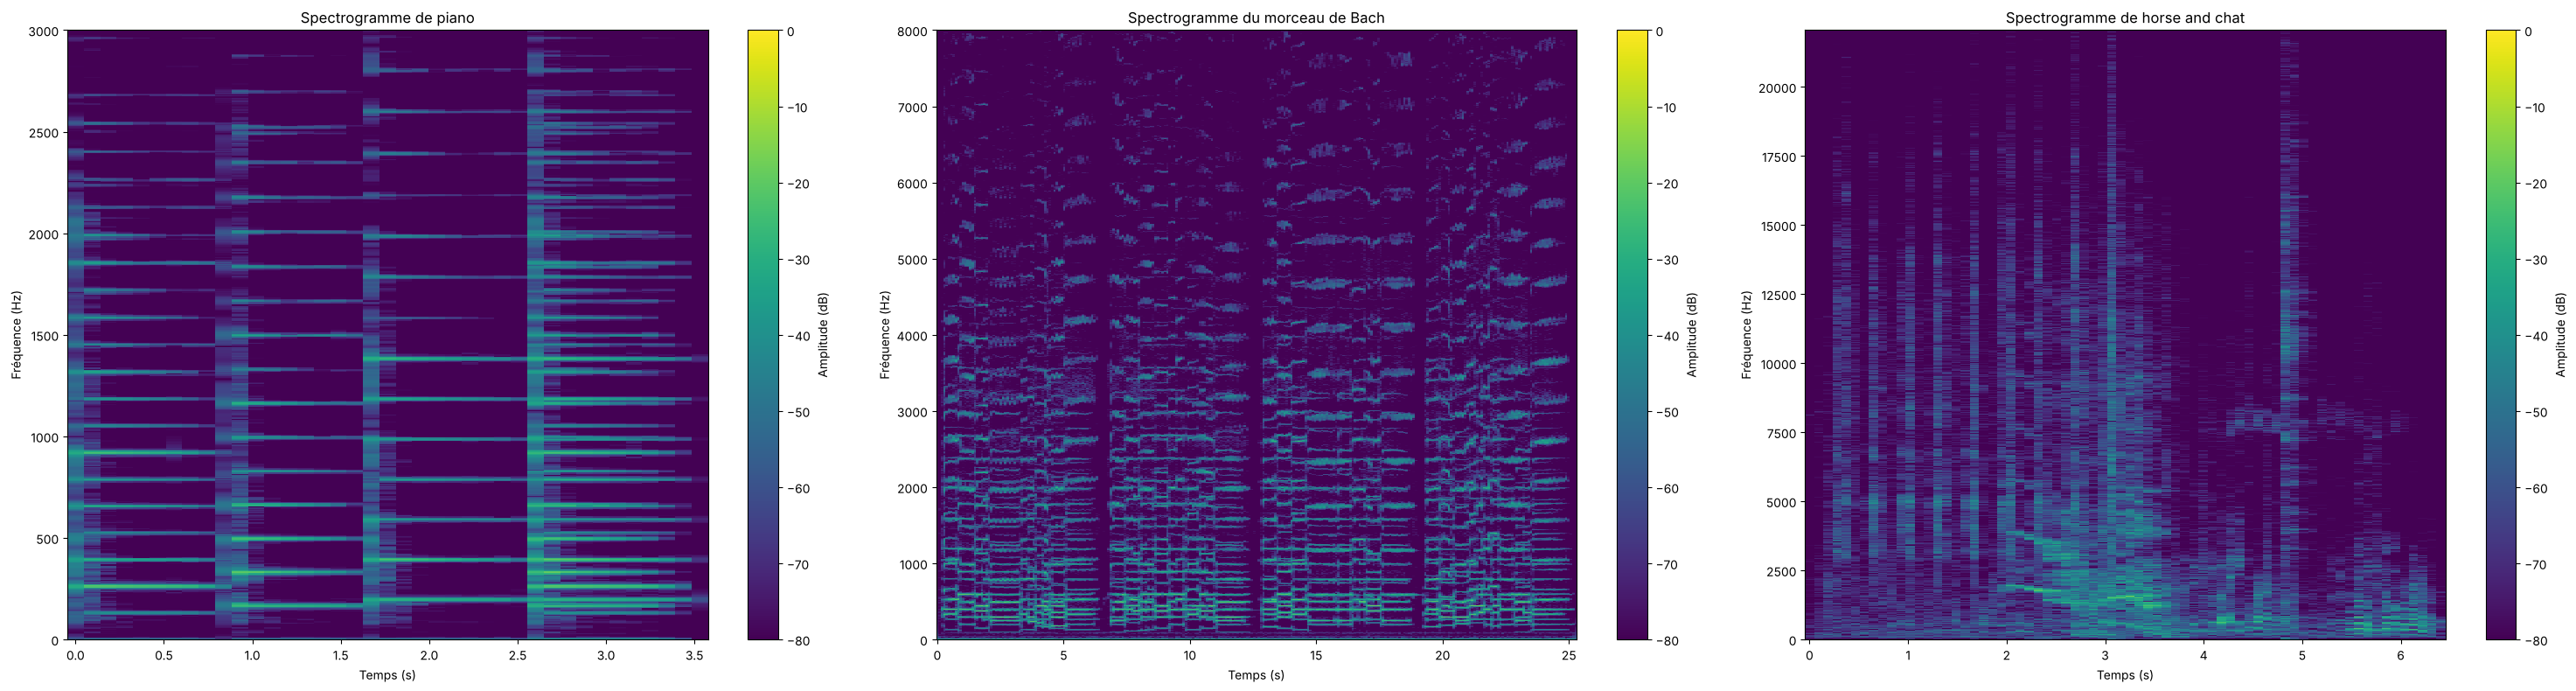

In [9]:
plt.figure(figsize=(30, 8))
# Spectrogramme piano
plt.subplot(1, 3, 1)
plt.pcolormesh(t_h_piano, STFT_h_piano, piano_h_db, shading='auto', cmap='viridis')
plt.ylim(0, 3000)
plt.clim(-80, 0)
plt.xlabel("Temps (s)")
plt.ylabel("Fréquence (Hz)")
plt.title("Spectrogramme de piano")
cbar1 = plt.colorbar()
cbar1.set_label("Amplitude (dB)")

# Spectrogramme de Bach
plt.subplot(1, 3, 2)
plt.pcolormesh(t_h_bach, STFT_h_bach, bach_h_db, shading='auto', cmap='viridis')
plt.ylim(0, 8000)
plt.clim(-80, 0)
plt.xlabel("Temps (s)")
plt.ylabel("Fréquence (Hz)")
plt.title("Spectrogramme du morceau de Bach")
cbar2 = plt.colorbar()
cbar2.set_label("Amplitude (dB)")

# Spectrogramme cheval and chat
plt.subplot(1, 3, 3)
plt.pcolormesh(t_h_anim, STFT_h_anim, anim_h_db, shading='auto', cmap='viridis')
plt.clim(-80, 0)
plt.xlabel("Temps (s)")
plt.ylabel("Fréquence (Hz)")
plt.title("Spectrogramme de horse and chat")
cbar3 = plt.colorbar()
cbar3.set_label("Amplitude (dB)")

plt.tight_layout()
plt.show()

##### 1.2.2 STFT à la main
Nous allons maintenant réaliser la STFT (Short-Time Fourier Transform) manuellement.

La STFT est définie par la formule suivante :
$$
F(\nu, b) = \int_{-\infty}^{+\infty} f(x) \, h(x - b) \, e^{-2 i \pi \nu x} \, dx
$$

où :  
- $f(x)$ est le signal à analyser,  
- $h(x-b)$ est une fenêtre centrée en \(b\),  
- $\nu$ représente la fréquence.  

En pratique, comme nous travaillons sur un signal discret, il n'est pas possible de calculer cette intégrale continue. Nous utilisons donc une approche numérique :  

1. Découper le signal en segments en appliquant une fenêtre sur chaque portion du signal
2. Déplacer la fenêtre le long du signal
3. Appliquer la Transformée de Fourier sur chaque segment  


In [10]:
# Transformée de Fourier discrète
def tf(x):
    n = len(x)

    # On conserve que la moitié car symétrie
    t = np.linspace(0, 1, n+1)[0:n]
    n_freqs = int(np.ceil(n/2))
    f = np.fft.fft(x)

    # On normalise et prend la partie réelle et imaginaire
    cos = np.real(f)[0:n_freqs]*2/n
    sin = -np.imag(f)[0:n_freqs]*2/n
    return  cos, sin, t

# STFT implémentée à la main
def stft_main(x, fenetre, taille, freq):
    n = len(x)

    # On définit la taille des morceaux
    taille_morceau = int(np.floor((n - fenetre)/taille)) + 1
    n_freqs = int(np.ceil(fenetre/2))

    # Initialisation de la matrice STFT
    S = np.zeros((n_freqs, taille_morceau))
    freqs = np.zeros((n_freqs, taille_morceau))

    # Boucle pour calculer la tf sur chaque morceau
    for i in range(taille_morceau):
        xi = x[taille * i:taille * i + fenetre]
        cos, sin, t = tf(xi)
        amp = np.sqrt(cos**2 + sin**2)
        S[:, i] = amp
        freqs[:, i] = np.fft.fftfreq(fenetre, 1/freq)[0:n_freqs]
    
    # Passage en dB 
    S_db = 20 * np.log10(S + 1e-12)
        
    return S, freqs

Nous avons appliqué notre fonction de STFT implémentée manuellement au signal de piano, puis comparé le résultat avec celui obtenu à l’aide de la fonction STFT de la bibliothèque SciPy. Les résultats obtenus sont globalement similaires. 

Cependant, notre implémentation manuelle se révèle moins performante et moins précise, comme en témoigne un spectrogramme moins lisible. Nous pouvons donc conclure que notre implémentation manuelle de la STFT est correcte, mais qu’elle pourrait être améliorée afin d’obtenir de meilleures performances et une meilleure précision.

[STFT] nperseg = 8192, noverlap = 4096


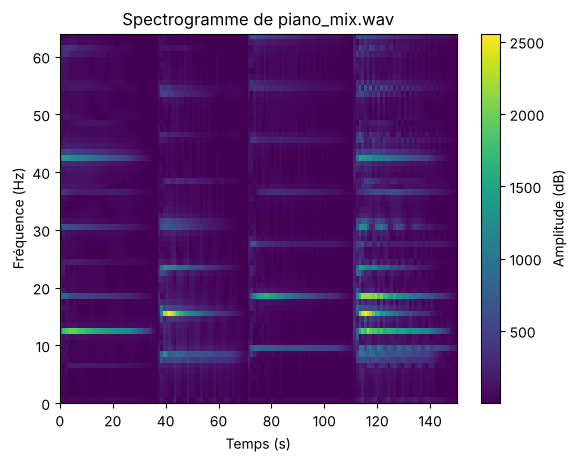

In [11]:
# Application de notre fonction en utilisant une fenêtre de Hann disponible dans scipy
taille_piano, overlap_piano = calculate_stft_params(extrait_piano,freq_piano)
fenetre = 2028
S, freq_S = stft_main(extrait_piano, fenetre, fenetre//2, freq_piano)

# Affichage du spectrogramme
plt.pcolormesh(S, shading='auto', cmap='viridis')
plt.ylim(0, 64)  # on n'a que 0–64 Hz
# plt.clim(-80, 0)  # même plage de couleurs (-80 dB à 0 dB)

plt.xlabel("Temps (s)")
plt.ylabel("Fréquence (Hz)")
plt.title("Spectrogramme de piano_mix.wav")

cbar = plt.colorbar()
cbar.set_label("Amplitude (dB)")

plt.show()

Nous disposons maintenant d'une matrice représentant l'évolution des fréquences en fonction du temps, c'est-à-dire le spectrogramme.  

Nous allons la décomposer en deux sous-matrices à l'aide de la factorisation en matrices non négatives.

Comme mentionné précédemment, notre matrice à la main n'est pas celle attendue. En effet, pour qu'elle ressemble à un spectrogramme nous avons dû nous mettre en 0 et 64 Hz plutôt que 0-2800 Hz, en plus des décibels qui se trouvent entre 0 et 2500 plutôt que -80 à 0 dB. Nous utiliserons donc par la suite celle de SciPy.

## 2. Décompisition NMF


La factorisation en matrices non négatives est une méthode puissante pour analyser les spectrogrammes. Elle permet de décomposer un spectrogramme en plusieurs bases fréquentielles, correspondant aux motifs caractéristiques du signal, et en leurs activations temporelles, qui indiquent quand ces motifs apparaissent

Ainsi, pour comprendre comment cette démarche fonctionne, nous avons tout d'abord utiliser la fonction préfaite NMF de la librairie sklearn.decomposition qui nous permet de récupérer très facilement les matrices D et A.


In [12]:
from sklearn.decomposition import NMF
'''
-- Fonction calculDA_viaNMF() --

Brief:
Applique une factorisation NMF (Non-negative Matrix Factorization) sur un spectrogramme
ou toute matrice non-négative M. La fonction utilise l'initialisation NNDSVD pour 
améliorer la convergence et obtient la matrice des sources (D) et la matrice d'activation des sources (A).

Retourne:
- D : matrice des spectres caractéristiques (m * k)
- A : matrice d'activation des sources dans le temps (k * n)

Paramètres:
- M : matrice d'entrée non-négative (ex: spectrogramme)
- e : tolérance pour la convergence de l'algorithme NMF (par défaut 1e-8)
- nCompos : nombre de composantes (sources) à extraire (par défaut 5)
'''
def calculDA_viaNMF(M, e=1e-8, nCompos=5):

    model = NMF(n_components=nCompos, init='nndsvd', random_state=0, tol=e)
    D = model.fit_transform(M)
    A = model.components_

    return D, A

Cette fonction, comme nous pouvons le voir utiliser différent paramètres. Tout d'abord, nous avons le nombre de composants puis un paramètre que nous n'avons pas encore vu jusque là, l'initialisation. En effet, ce paramètre correspond à comment nous allons initialiser nos matrices D et A à l'itération 0. Ainsi, nous pouvons avoir des valeurs comme 'random' qui vont initialiser de façon aléatoire nos matrices de départ. Nous utilisons ici l'initialisation nndvsvd qui signifie "onnegative Double Singular Value Decomposition" puisqu'elle permet une meilleure stabilité en général. Enfin, le paramètre de random_state est mis à 0 car il s'agit d'un paramètre utile lorsque nous avons une initialisation spécifique (nndsvdar ou random) et tol correspond à la tolérance, la valeur où on accepte de dire que nos matrices ont convergés et sont "suffisantes".

Maintenant que nous avons nos matrices D et A, nous pouvons passer à la suite, néanmoins, il est intéressant de comprendre comment cette décomposition NMF fonctionne et surtout, comment les différentes façon de le faire. Nous avons étudié trois approches différentes :

### 2.1 La méthode des Moindres Carrés Alternés

Cette première fonction implémente la méthode des Moindres Carrés Alternés. Contrairement aux méthodes que nous aborderons par la suite, il s'agit ici d'une approche purement géométrique puisque son objectif est de minimiser la distance euclidienne, c'est-à-dire la différence brute, entre notre matrice originale M et sa reconstruction.

Le but ici n'est pas de mettre à jour les deux matrices simultanément mais bien de d'abord calculer la matrice A avec notre matrice D puis calculer la matrice D avec notre matrice A. En effet, à chaque itération, nous fixons d'abord la matrice D pour calculer la meilleure matrice A possible via une solution analytique exacte utilisant l'inversion de matrice, puis nous procédons inversement en fixant la nouvelle matrice A pour recalculer D.

Il faut néanmoins faire attention puisque ces calculs peuvent aboutir à des valeurs négatives. Nous devons donc manuellement forcer une contrainte de non-négativité après chaque calcul pour respecter le principe de base de la NMF. 

Nous avons ainsi pu constater qu'il s'agissait d'une méthode efficace qui converge généralement vite, mais qui reste sensible aux valeurs aberrantes puisqu'elle cherche à minimiser l'erreur totale brute sur les plus grandes valeurs. Ainsi dans notre cas d'étude sur des sons, cela a donc tendance à préférer corriger les erreurs sur les basses fréquences plutôt que sur les silences puisque l'erreur sera plus grande alors même qu'il s'agit d'erreur pratiquement imperceptible pour l'oreille humaine tandis que les silences seront moins corrigés alors même qu'une petite erreur dans un silence s'entendra bien plus. Cela se comprend puisque notre oreille est logarithmique.

Cette méthode est donc efficace même si elle est générallement plus utilisée pour le trairement d'image ou lorsqu'il s'agit d'un bruit blanc uniforme (bruit gaussien).




---




Puisque nous utilisons la méthode dite "analytique" et donc par formule, il nous faut comprendre d'où vient la formule:

Cette démonstration vise à trouver les matrices $D$ et $A$ qui minimisent la distance euclidienne avec la matrice cible $M$, en utilisant une approche par gradients successifs et alternés entre les matrices D et A.

Pour dériver des fonctions de coût matricielles, nous utilisons les propriétés de la trace ($\text{Tr}$).
Voici les propriétés et les gradients usuels nécessaires pour cette démonstration (où $X$ est la variable et $S$ est une matrice symétrique) :

1.  **Lien Norme/Trace :** $||X||_F^2 = \text{Tr}(X^T X)$
2.  **Linéarité :** $\text{Tr}(A + B) = \text{Tr}(A) + \text{Tr}(B)$
3.  **Propriété cyclique :** $\text{Tr}(XYZ) = \text{Tr}(ZXY) = \text{Tr}(YZX)$
4.  **Gradient linéaire (forme $\text{Tr}(BX)$) :** $\nabla_X \text{Tr}(B X) = B^T$
5.  **Gradient linéaire (forme $\text{Tr}(XB)$) :** $\nabla_X \text{Tr}(X B) = B^T$
6.  **Gradient quadratique (forme $X^T S X$) :** $\nabla_X \text{Tr}(X^T S X) = 2SX$
7.  **Gradient quadratique (forme $X S X^T$) :** $\nabla_X \text{Tr}(X S X^T) = 2XS$

Ceux-ci ont été récupérés via le Cookbook disponible dans la section `Bibliographie`.


Nous cherchons tout d'abord à minimiser la norme de Frobenius au carré de l'erreur de reconstruction entre $M$ et $DA$. Nous ajoutons ensuite un facteur $\frac{1}{2}$ pour simplifier les futures dérivées.

$$J(D, A) = \frac{1}{2} || M - DA ||_F^2$$

Reformulons avec la trace (Identité 1) pour permettre la dérivation matricielle :

$$J(D, A) = \frac{1}{2} \text{Tr}\left( (M - DA)^T (M - DA) \right)$$

Développons l'expression à l'intérieur de la trace en utilisant $(X-Y)^T = X^T - Y^T$ et $(XY)^T = Y^T X^T$ :

$$(M - DA)^T (M - DA) = (M^T - A^T D^T)(M - DA)$$
$$= M^T M - M^T DA - A^T D^T M + A^T D^T DA$$

En appliquant la trace et sa linéarité (Identité 2) à l'expression globale :

$$2J(D, A) = \text{Tr}(M^T M) - \text{Tr}(M^T DA) - \text{Tr}(A^T D^T M) + \text{Tr}(A^T D^T DA)$$

Utilisons la propriété $\text{Tr}(X) = \text{Tr}(X^T)$ sur le troisième terme :
$\text{Tr}(A^T D^T M) = \text{Tr}((DA)^T M) = \text{Tr}(M^T DA)$.
Les deux termes centraux sont donc identiques.

La fonction de coût finale, prête à être dérivée, est :

$$J(D, A) = \frac{1}{2} \text{Tr}(M^T M) - \text{Tr}(M^T DA) + \frac{1}{2} \text{Tr}(A^T D^T DA)$$


Le problème d'optimisation n'est pas convexe pour $D$ et $A$ simultanément. Ainsi, il nous est nécessaire de d'abord calculer $D$ puis calculer $A$ :
1.  **Étape A :** Fixer $D$ comme une constante et trouver le $A$ qui annule le gradient ($\nabla_A J = 0$).
2.  **Étape D :** Fixer $A$ comme une constante et trouver le $D$ qui annule le gradient ($\nabla_D J = 0$).


Nous dérivons ensuite $J$ par rapport à $A$. Le premier terme $\frac{1}{2} \text{Tr}(M^T M)$ ne dépend pas de A, il est constant et sa dérivée est donc nulle.

$$\nabla_A J = \nabla_A \left[ -\text{Tr}((M^T D)A) \right] + \nabla_A \left[ \frac{1}{2} \text{Tr}(A^T (D^T D) A) \right]$$


* **Terme linéaire :** $-\text{Tr}((M^T D)A)$.
    Utilisons le Gradient linéaire 4 avec $X=A$ et la constante $B=M^T D$.
    $$\nabla_A [...] = -(M^T D)^T = -D^T M$$

* **Terme quadratique :** $\frac{1}{2} \text{Tr}(A^T (D^T D) A)$.
    Posons $S = D^T D$. Remarquons que $S$ est symétrique ($S^T = (D^T D)^T = D^T D = S$).
    Utilisons le Gradient quadratique 6 avec $X=A$.
    $$\nabla_A [...] = \frac{1}{2} (2 (D^T D) A) = D^T D A$$

Il nous suffit ensuite d'assembler le gradient complet et de le fixer à zéro pour trouver le minimum :

$$\nabla_A J = -D^T M + D^T D A = 0$$
$$D^T D A = D^T M$$

Pour isoler $A$, nous multiplions à gauche par l'inverse de la matrice $(D^T D)$ :

> **Solution analytique pour A :**
> $$\mathbf{A = (D^T D)^{-1} D^T M}$$

Nous dérivons maintenant $J$ par rapport à $D$. Le terme $\frac{1}{2} \text{Tr}(M^T M)$ est constant et disparaît.

Pour simplifier les calculs de dérivées, il nous faut utiliser d'abord la propriété cyclique de la trace (Identité 3) sur la fonction de coût pour placer $D$ en début ou fin des produits matriciels.

* Terme central : $-\text{Tr}(M^T DA) \rightarrow -\text{Tr}(DA M^T)$
* Dernier terme : $\frac{1}{2} \text{Tr}(A^T D^T DA) \rightarrow \frac{1}{2} \text{Tr}(D A A^T D^T)$

La fonction à dériver par rapport à D est :
$$J_{pour D} \propto -\text{Tr}(D(A M^T)) + \frac{1}{2} \text{Tr}(D (A A^T) D^T)$$

$$\nabla_D J = \nabla_D \left[ -\text{Tr}(D (A M^T)) \right] + \nabla_D \left[ \frac{1}{2} \text{Tr}(D (A A^T) D^T) \right]$$

* **Terme linéaire :** $-\text{Tr}(D (A M^T))$.
    Utilisons le Gradient linéaire 5 avec $X=D$ et la constante $B=A M^T$.
    $$\nabla_D [...] = -(A M^T)^T = -M A^T$$

* **Terme quadratique :** $\frac{1}{2} \text{Tr}(D (A A^T) D^T)$.
    Posons $S = A A^T$. Remarquons que $S$ est symétrique.
    Utilisons le Gradient quadratique 7 avec $X=D$.
    $$\nabla_D [...] = \frac{1}{2} (2 D (A A^T)) = D A A^T$$


On reproduit ce qu'on a fait avant en assemblant le gradient complet et en le fixant à zéro :

$$\nabla_D J = -M A^T + D A A^T = 0$$
$$D A A^T = M A^T$$

Pour isoler $D$, nous multiplions à droite par l'inverse de la matrice $(A A^T)$ :

> **Solution analytique pour D :**
> $$\mathbf{D = M A^T (A A^T)^{-1}}$$

In [13]:
import scipy.linalg
'''
-- Fonction calculDA_viaMoindresCarres() --

Brief:
Applique une factorisation approximative de la matrice non-négative M sous la forme
M ≈ D @ A en utilisant une méthode de moindres carrés alternés (ALS) [méthode analytique != additive ou multiplicative]. À chaque
itération, A est mise à jour en fonction de D, puis D est mise à jour en fonction de A.
Les deux matrices sont forcées à rester non-négatives après chaque mise à jour.

Retourne:
- D : matrice des bases (motifs fréquentiels) de taille (m * k)
- A : matrice d’activation des composantes de taille (k * n)
- iter : nombre d’itérations effectuées avant convergence
- normesObtenues : Liste des normes obtenues au fil des itérations

Paramètres:
- M : matrice d’entrée non-négative (ex: spectrogramme)
- nCompos : nombre de composantes à extraire
- eps : tolérance de convergence basée sur la variation entre itérations
- max_iter : nombre maximum d’itérations

Précision:
Ici, nous avons préféré utiliser la méthode analytique au lieu des méthodes additive et multiplicative. Cela s'explique par le fait
que c'est la solution la plus adaptée à notre problème. Nous cherchons à converger vite et trouver le minimum et non pas à explorer.
'''
def calculDA_viaMoindresCarres(M, nCompos, eps=1e-8, max_iter=250):
    
    freq, temps = M.shape

    # Pour que D*A soit proche de M dès le début et accélere la convergence
    moy = np.sqrt(M.mean() / nCompos)

    D = np.random.rand(freq, nCompos) * moy
    A = np.random.rand(nCompos, temps) * moy

    # Pour garder la contrainte de >=0
    D = np.maximum(D, 1e-10)
    A = np.maximum(A, 1e-10)

    # On initialise conv à Infini pour être certain d'entrer dans la boucle
    conv = float(np.inf)
    iter = 0

    normesObtenues = []

    while conv > eps and iter < max_iter:
        Dold = D
        Aold = A

        Dt_D = D.T@D
        Dt_M = D.T@M
        A = np.linalg.pinv(Dt_D)@Dt_M # Assurer la stabilité de l'inversion
        A = np.maximum(A, 1e-10)

        M_At = M@A.T
        A_At = A@A.T
        D = M_At@np.linalg.pinv(A_At) # Assurer la stabilité de l'inversion
        D = np.maximum(D, 1e-10)        

        # Calcul du résultat de la convergence via la norme de Frobenius
        conv = scipy.linalg.norm(Dold@Aold - D@A)
        normesObtenues.append(conv)

        iter+=1

    return D, A, iter, normesObtenues

### 2.2 Méthode de la Divergence de Itakura-Saito

Suite à l'approche géométrique des moindres carrés, nous nous sommes tournés vers la méthode basée sur la Divergence d'Itakura-Saito, une approche très spécifique issue du traitement du signal audio.

La particularité fondamentale de cette méthode est son invariance à l'échelle. Il s'agit là d'une propriété fondammentale puisqu'elle répond aux limitations que nous avons pu rencontrer avec la méthode des moindres carrés sur les sons faibles et les silences. En effet, cette méthode va corriger les sons non pas sur la différence absolue, mais sur le rapport entre la valeur réelle et la valeur reconstruite, permettant ainsi d'assurer la qualité de la reconstruction.

C'est une propriété essentielle en audio, car cela signifie qu'une erreur relative sur un signal faible sera aussi importante qu'une erreur sur un signal fort. Cela mime le fonctionnement logarithmique de l'oreille humaine, expliquant ainsi pourquoi elle est très utilisée sur les signaux sonores.

Pour calculer nos matrices D et A, nous utilisons une implémentation dites multiplicative puisque l'on vient ajuster progressivement les matrices avec un facteur de correction plutôt que de recalculer une solution exacte comme nous avons pu le faire avant. Les formules sont cependant complexes, faisant intervenir des divisions par le carré de la reconstruction, ce qui rend l'algorithme mathématiquement très sensible lorsque les valeurs approchent de zéro.

Ainsi, pour éviter que l'algorithme ne diverge, il est très important d'initialiser nos matrices correctement. En effet, cette méthode est très sensible à son initialisation de départ et donc très instable numériquement à cause de ce risque de divergence.

In [14]:
'''
-- Fonction calculDA_viaItakuraSaito() --

Brief:
Applique une factorisation approximative de la matrice non-négative M sous la forme
M ≈ D @ A en utilisant une méthode de divergence de Itakura Saito (ISD) pour optimiser
la convergence. À chaque itération, A est mise à jour en fonction de D, puis D est 
mise à jour en fonction de A. Les deux matrices sont forcées à rester non-négatives après chaque mise à jour.

Retourne:
- D : matrice des bases (motifs fréquentiels) de taille (m * k)
- A : matrice d’activation des composantes de taille (k * n)
- iter : nombre d’itérations effectuées avant convergence
- normesObtenues : Liste des normes obtenues au fil des itérations

Paramètres:
- M : matrice d’entrée non-négative (ex: spectrogramme)
- nCompos : nombre de composantes à extraire
- eps : tolérance de convergence basée sur la variation entre itérations
- max_iter : nombre maximum d’itérations
'''
def calculDA_viaItakuraSaito(M, nCompos, eps=1e-8, max_iter=250):
    
    freq, temps = M.shape

    # Pour que D*A soit proche de M dès le début et accélere la convergence
    moy = np.sqrt(M.mean() / nCompos)

    D = np.random.rand(freq, nCompos) * moy
    A = np.random.rand(nCompos, temps) * moy

    # Pour garder la contrainte de >=0
    D = np.maximum(D, 1e-10)
    A = np.maximum(A, 1e-10)

    # On initialise conv à Infini pour être certain d'entrer dans la boucle
    conv = float(np.inf)
    iter = 0

    normesObtenues = []

    while conv > eps and iter < max_iter:
        Dold = D
        Aold = A

        # Il faut dérivé (x/y - log(x/y) - y) par rapport à y => y-x / y**2
        # On obtient ainsi 1/y - x/y**2
        diviseur_DA = (D@A)

        # D.T pour avoir la bonne taille
        numeA = D.T@(M/(diviseur_DA**2)) # M/(diviseur_DA**2) <=> x/y*2
        denumA = D.T@(1/diviseur_DA) # M/(diviseur_DA) <=> 1/y
        A = A * (numeA/denumA)
        A = np.maximum(A, 1e-10)

        # Formule de calcul de D selon IS Divergence
        diviseur_DA = (D@A)
        numeD = (M/(diviseur_DA**2))@A.T
        denumD = (1/diviseur_DA)@A.T
        D = D * (numeD/denumD)
        D = np.maximum(D, 1e-10)        


        conv = scipy.linalg.norm(Dold@Aold - D@A)
        normesObtenues.append(conv)

        iter+=1

    return D, A, iter, normesObtenues

### 2.3 Méthode de la Divergence de Kullback-Leibler

Enfin, nous nous sommes penchés sur la méthode basée sur la Divergence de Kullback-Leibler. Nous avons ainsi pu voir que cette approche est souvent considérée comme le meilleur compromis généraliste, se positionnant entre la rigidité de l'approche géométrique des moindres carrés et l'extrême sensibilité aux ratios de la méthode d'Itakura-Saito. Il est d'ailleurs intéressant de noter qu'il s'agit de la méthode utilisée par la fonction NMF de la librairie de sklearn.decomposition que nous avons vu plus tôt. Elle est donc bien plus utilisable en règle générale.

À la différence des autres méthodes, la Divergence de KL repose sur une approche plus statistiques. L'objectif n'est plus de minimiser une distance ou un rapport, mais plutôt de minimiser une perte d'information lorsque l'on tente d'approximer le signal original par notre reconstruction. Nous avons donc vu que cette méthode est très efficace lorsque les données du spectrogramme peuvent être interprétées comme des comptages d'énergie, suivant implicitement une distribution statistique appelée loi de Poisson. Nous ne nous attarderons pas dessus puisque cela dépasse notre champ de connaissance pour ce projet mais il est toujours intéressant de le noter.

De plus, comme pour la méthode d'Itakura-Saito, le calcul des matrices D et A est dites multiplicativee puisqu'elle vient ajuster progressivement les valeurs via un facteur de correction. Néanmoins, il est intéressant de noter dans l'implémentation une différence très importante en termes de complexité de calcul. En effet, une optimisation mathématique permet ici de remplacer certaines multiplications matricielles coûteuses (nécessaires pour Itakura-Saito) par de simples sommes. De ce fait, cela rend ainsi cet algorithme généralement plus rapide par itération et numériquement plus stable que celui d'Itakura-Saito, tout en offrant une meilleure gestion de la dynamique sonore que les moindres carrés.

De ce fait, nous pouvons comprende pourquoi cette méthode est celle utilisée en général, de par son efficacité et sa stabilité et ce, peu importe le type de signal sur lequel on travaille.

In [15]:
'''
-- Fonction calculDA_viaKullbackLeibler() --

Brief:
Applique une factorisation approximative de la matrice non-négative M sous la forme
M ≈ D @ A en utilisant une méthode de divergence de Kullback Leibler (KLD) pour optimiser
la convergence. À chaque itération, A est mise à jour en fonction de D, puis D est 
mise à jour en fonction de A. Les deux matrices sont forcées à rester non-négatives après chaque mise à jour.

Retourne:
- D : matrice des bases (motifs fréquentiels) de taille (m * k)
- A : matrice d’activation des composantes de taille (k * n)
- iter : nombre d’itérations effectuées avant convergence
- normesObtenues : Liste des normes obtenues au fil des itérations

Paramètres:
- M : matrice d’entrée non-négative (ex: spectrogramme)
- nCompos : nombre de composantes à extraire
- eps : tolérance de convergence basée sur la variation entre itérations
- max_iter : nombre maximum d’itérations
'''
def calculDA_viaKullbackLeibler(M, nCompos, eps=1e-8, max_iter=250):
    
    freq, temps = M.shape

    # Pour que D*A soit proche de M dès le début et accélere la convergence
    moy = np.sqrt(M.mean() / nCompos)

    D = np.random.rand(freq, nCompos) * moy
    A = np.random.rand(nCompos, temps) * moy

    # Pour garder la contrainte de >=0
    D = np.maximum(D, 1e-10)
    A = np.maximum(A, 1e-10)

    # On initialise conv à Infini pour être certain d'entrer dans la boucle
    conv = float(np.inf)
    iter = 0

    normesObtenues = []

    while conv > eps and iter < max_iter:
        Dold = D
        Aold = A

        # Formule de calcul de A selon KL Divergence
        # Il faut calculer la dérivée de (xlog(yx​)−x+y) par rapport à y => 1 - x/y

        diviseur_DA = D@A + 1e-10
        # D.T pour avoir la bonne taille
        numeA = D.T@(M/diviseur_DA)
        denumA = np.sum(D, axis=0)[:, None]     # <=> D.T@np.ones_like(M) mais moins couteux (optimisation trouvée par IA)
        A = A * (numeA/denumA)

        A = np.maximum(A, 1e-10)

        # Formule de calcul de D selon KL Divergence
        diviseur_DA = D@A + 1e-10
        numeD = (M/diviseur_DA)@A.T
        denumD = np.sum(A, axis=1)[None, :]    # <=> np.ones_like(M)@A.T mais moins couteux (optimisation trouvée par IA)
        D = D * (numeD/denumD)

        D = np.maximum(D, 1e-10)        

        conv = scipy.linalg.norm(Dold@Aold - D@A)
        normesObtenues.append(conv)

        iter+=1

    return D, A, iter, normesObtenues

### 2.4 Comparaison des résultats

Maintenant que nous pu voir ces trois algorithme, il est intéressant de les comparer entre eux. Pour cela, nous allons utiliser une fonction de comparaison basée sur le rapport Signal-sur-Bruit (SNR). Cette fonction calcule, pour chaque algorithme, le rapport entre la puissance totale du signal original M et la puissance du "bruit", défini ici comme l'erreur résiduelle de reconstruction (M−D×A).

**Attention:: Il ne s'agit pas dutout d'une valeur que l'on peut prendre comme référence pour la comparaison de ces algorithmes puisque notre comparaison se base sur des calculs spécifiques et dont certaines méthodes n'ont pas pour objectif d'optimiser ces résultats.**

Afin de faciliter l'interprétation graphique, ces rapports sont convertis en décibels (dB). Plus la valeur en dB est élevée, plus l'énergie de la reconstruction est fidèle au signal d'origine.

In [16]:
"""
-- Fonction comparaisonMeilleurAlgo() --

Brief:
Comparaison des différents algorithmes MNF via la formule Ps/Pb avec la puissance du Signal M et la puissance du Bruit M-D@A.
Affichage ensuite du graphique de comparaison pour une meilleure visualisation des résultats.

Retourne:
- resultats : Dictionnaire des résultats {"Abréviation des noms d'algos": valeur du ratio}

Paramètres:
- M : matrice d’entrée non-négative (ex: spectrogramme)
- nCompos : nombre de composantes à extraire
- eps : tolérance de convergence basée sur la variation entre itérations
- max_iter : nombre maximum d’itérations
"""
def comparaisonMeilleurAlgo(M, nCompos, eps=1e-8, max_iter=250):

    # On récupère chaque résultat des fonctions
    D_MC, A_MC, _, _ = calculDA_viaMoindresCarres(M, nCompos, eps, max_iter)
    D_KL, A_KL, _, _ = calculDA_viaKullbackLeibler(M, nCompos, eps, max_iter)
    D_IS, A_IS, _, _ = calculDA_viaItakuraSaito(M, nCompos, eps, max_iter)

    # On calcule l'erreur pour chaque fonction
    Erreur_MC = M - (D_MC@A_MC)
    Erreur_KL = M - (D_KL@A_KL)
    Erreur_IS = M - (D_IS@A_IS)

    # Pour avoir la comparaison, on va utiliser Ps / Pb donc on convertit en puissance:

    Puissance_SignalM = np.sum(M**2) # calcul de Ps

    Puissance_Bruit_MC = np.sum(Erreur_MC**2)
    Puissance_Bruit_KL = np.sum(Erreur_KL**2)
    Puissance_Bruit_IS = np.sum(Erreur_IS**2)

    
    # On traduit en décibel pour avoir des valeurs plus compréhensible

    ratio_MC = 10 * np.log10(Puissance_SignalM / Puissance_Bruit_MC)
    ratio_KL = 10 * np.log10(Puissance_SignalM / Puissance_Bruit_KL)
    ratio_IS = 10 * np.log10(Puissance_SignalM / Puissance_Bruit_IS)


    # Maintenant qu'on a les valeurs, on en fait un dictionnaire
    resultats = {
        "MC": ratio_MC,
        "KL": ratio_KL,
        "IS": ratio_IS
    }

    # Ensuite on va faire les affichages par liste

    noms = resultats.keys()
    ratios = resultats.values()

    # Gestion de l'affichage (faites via IA pour une meilleure qualité)
    barres = plt.bar(noms, ratios, color=['blue', 'green', 'red'])

    plt.ylabel('Ratio Ps/Pb (dB)')
    plt.title('Comparaison des différents algorithmes MNF')
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    
    # Afficher les valeurs sur les barres
    for b in barres:
        yval = b.get_height()
        plt.text(b.get_x() + b.get_width()/2, yval + 0.5, f"{yval:.1f} dB", ha='center', va='bottom', fontweight='bold')
        
    plt.show()

    
    # on renvoie le dictionnaire
    return resultats

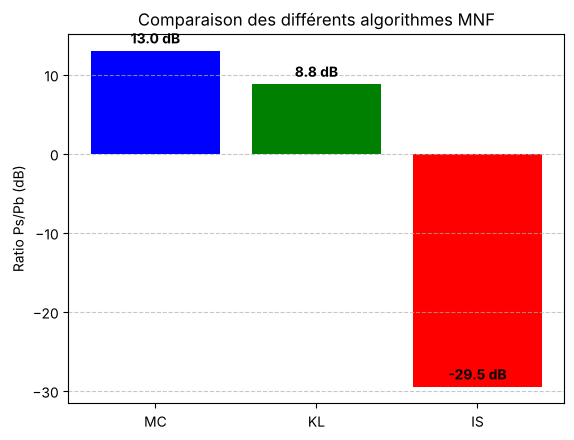

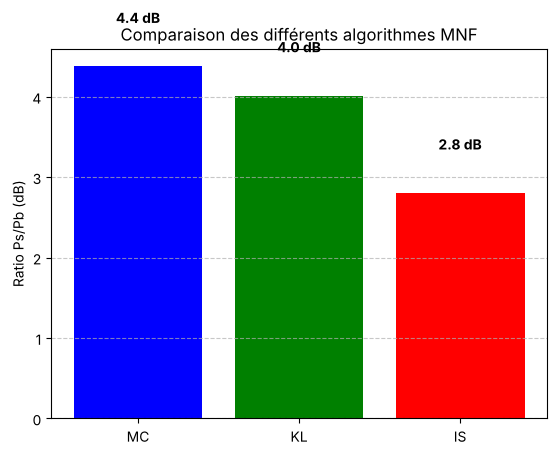

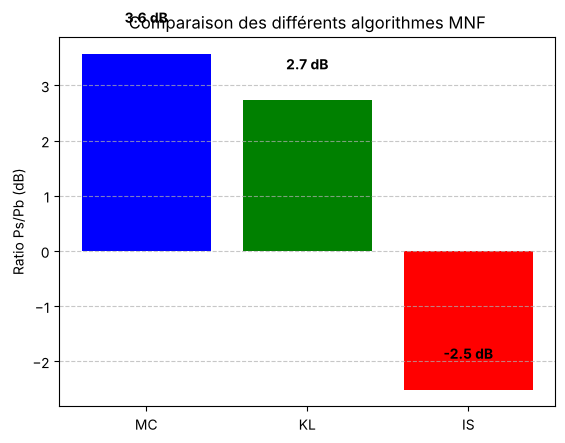

In [17]:
resultats_Piano = comparaisonMeilleurAlgo(M_piano, eps=1e-8, nCompos=3)
resultats_Back = comparaisonMeilleurAlgo(M_bach, eps=1e-8, nCompos=3)
resultats_Anim = comparaisonMeilleurAlgo(M_anim, eps=1e-8, nCompos=3)

Avec les graphiques que l'on obtient, nous pouvons voir des résultats claires et assez logique. En effet, la méthode des Moindres Carrés (MC) obtient systématiquement le score le plus élevé, suivie de près par la méthode de Kullback-Leibler (KL), tandis que la Divergence d'Itakura-Saito (IS) affiche un score nettement inférieur sur cette échelle. 

Nous pouvons facilement comprendre ces résultats de par la définition mathématique de notre comparaison. En effet, la formule du SNR utilisée ici repose sur la minimisation de l'énergie globale de l'erreur (la somme des carrés). Or, l'algorithme des Moindres Carrés est spécifiquement conçu pour optimiser ce critère précis. De ce fait, il est tout à fait naturel qu'il soit le mieux noté sur cette comparaison spécifique.

À l'inverse, la méthode d'Itakura-Saito, qui sacrifie la précision sur les fortes amplitudes pour mieux préserver les détails perceptifs (dans le sens où l'erreur est importante) dans les signaux faibles, se retrouve avec un score bien plus bas car il n'a pas pour but d'optimiser une mesure d'énergie globale.

Ainsi, il est important de comprendre que ces graphiques mesurent d'une certaine façon une métrique spécifique mais que celle-ci ne correspond pas forcément à la qualité finale que nous obtiendrons ensuite pour notre oreille humaine.

## 3. Recomposition

La fonction recomposition constitue la dernière étape du traitement.
Son rôle est de reconstruire les signaux audio individuels à partir des matrices
issues de la NMF.

In [18]:
'''
-- Fonction recomposition() --

Brief:
Reconstruit les signaux temporels à partir de la factorisation NMF d'un spectrogramme.
À partir des matrices A (activations temporelles) et D (spectres sources), la fonction applique
un masque spectral à la STFT complexe originale pour reconstituer chaque source dans le temps.

Retourne: 
- Une liste de signaux temporels reconstruits (un signal par source).

Paramètres:
- A : matrice d'activation des sources (m * k)
- D : matrice liste des sources (k * n)
- MatriceComplexeSpectrogramme : Matrice complexe correspondant à la STFT (Short Time Fourier Transform) du signal d'origine
- param... : doivent correspondrent aux paramètres utilisés lors de la STFT de base.

'''
def recomposition(A, D, MatriceComplexeSpectrogramme, paramsFS=44100, paramWindow="hann", paramNperseg=1024, paramNoverlap=None):
    
    # Vérification de la compatibilité des dimensions entre D et A
    # D : (fréquences × sources), A : (sources × temp)
    if D.shape[1] != A.shape[0]:
        raise Exception(f"Erreur, taille de matrice différente : ({A.shape[0]}) et ({D.shape[1]})")
    
    # Si le recouvrement n'est pas défini, on prend 50% de la fenêtre
    if paramNoverlap is None:
        paramNoverlap = paramNperseg // 2

    signauxFinaux = []

    nbSources = D.shape[1]
    V = D@A + 1e-12 # pour éviter la division par 0 dans le calcul du masque

    for i in range(nbSources):
        # Produit extérieur entre la base spectrale et son activation temporelle
        V_i = np.outer(D[:, i], A[i, :])

        masque = V_i / V # Masque pour avoir une qualité des audios améliorées

        # On ajoute la phase à notre signal pour l'istft (on présume que la phase du signal d'origine suffit)
        z = masque * MatriceComplexeSpectrogramme
        
         # Reconstruction du signal temporel par STFT Inverse (ISTFT)
        _, signal_audio_Reconstruit = sc.signal.istft(z, fs=paramsFS, window=paramWindow, nperseg=paramNperseg, noverlap=paramNoverlap)
        
        # Ajout du signal reconstruit à la liste finale
        signauxFinaux.append(signal_audio_Reconstruit)

    return signauxFinaux

L’objectif de la fonction recomposition est de reconstruire les signaux audio individuels à partir des résultats de la décomposition NMF, en exploitant les informations spectrales et temporelles extraites du signal mélangé.
Elle vise ainsi à permettre une séparation réaliste des sources, tout en conservant les caractéristiques essentielles du signal original, notamment la phase.<br><br>

Dans un premier temps, nous vérifions la compatibilité des dimensions des matrices issues de la NMF afin de garantir une reconstruction correcte des signaux.<br>
Le spectrogramme global est ensuite estimé par multiplication matricielle entre le dictionnaire spectral et les activations temporelles, avec l’ajout d’un terme de régularisation afin d’éviter les divisions par zéro lors des calculs ultérieurs.<br><br>

Dans un second temps, un spectrogramme est reconstruit pour chaque source séparément à l’aide d’un produit extérieur entre la base spectrale correspondante et son activation temporelle.<br>
Des masques spectraux sont alors calculés afin d’estimer la contribution de chaque source dans le spectrogramme total.<br>
Ces masques sont appliqués au spectrogramme complexe du signal original, ce qui permet de conserver la phase, élément indispensable pour obtenir une reconstruction audio réaliste.<br>
Enfin, une transformée de Fourier inverse à court terme (ISTFT) est appliquée afin de revenir dans le domaine temporel et d’obtenir les signaux audio reconstruits.

In [19]:
def afficher_NMF(W, A, M, freq, t):
    """
    W : matrice (freq × k)
    A : matrice (k × temps)
    M : spectrogramme original (freq × temps)
    freq : vecteur des fréquences STFT
    t : vecteur des temps STFT
    """
    
    k = A.shape[0]   # nombre de composantes
    
    # Reconstruction pour l'affichage
    M_recons = W @ A
    
    fig = plt.figure(figsize=(15, 10))

    # --- 1) Activations temporelles A ---
    axA = plt.subplot2grid((5,4), (0,1), colspan=3)
    axA.imshow(A, aspect='auto', origin='lower',extent=[t[0], t[-1], 0, k], cmap='jet')
    plt.title("Temporal activations H")
    plt.ylabel("Composante")
    
    # --- 2) Dictionnaire W ---
    axD = plt.subplot2grid((5,4), (1,0), rowspan=4)
    plt.imshow(W, aspect='auto', origin='lower',extent=[0, k, freq[0], freq[-1]], cmap='jet')
    plt.title("Dictionary W")
    plt.xlabel("Composante")
    plt.ylabel("Hz")
    plt.ylim(0, 3000)

    # --- 3) Spectrogramme reconstruit ---
    axG = plt.subplot2grid((5,4), (1,1), colspan=3, rowspan=4)
    axG.imshow(M_recons, aspect='auto', origin='lower',extent=[t[0], t[-1], freq[0], freq[-1]], cmap='jet')
    plt.title("Reconstructed Spectrogram W × H")
    plt.xlabel("Time")
    plt.ylabel("Hz")
    plt.ylim(0, 3000)
    plt.tight_layout()
    plt.show()


D’après nos analyses, l’interprétation des résultats de la NMF nécessite une visualisation adaptée, les matrices obtenues étant difficiles à exploiter directement sous forme numérique.
Nous avons donc utilisé la fonction afficher_NMF afin de représenter graphiquement les composantes extraites par la NMF, leur évolution temporelle ainsi que le spectrogramme reconstruit.<br><br>
Cette fonction nous permet de mieux comprendre la structure des sources séparées et d’identifier leur contribution dans le temps et dans le domaine fréquentiel.<br>
La reconstruction du spectrogramme constitue également un moyen d’évaluer visuellement la qualité de la décomposition.
Ainsi, cette fonction joue un rôle central dans l’analyse et la validation des résultats obtenus.

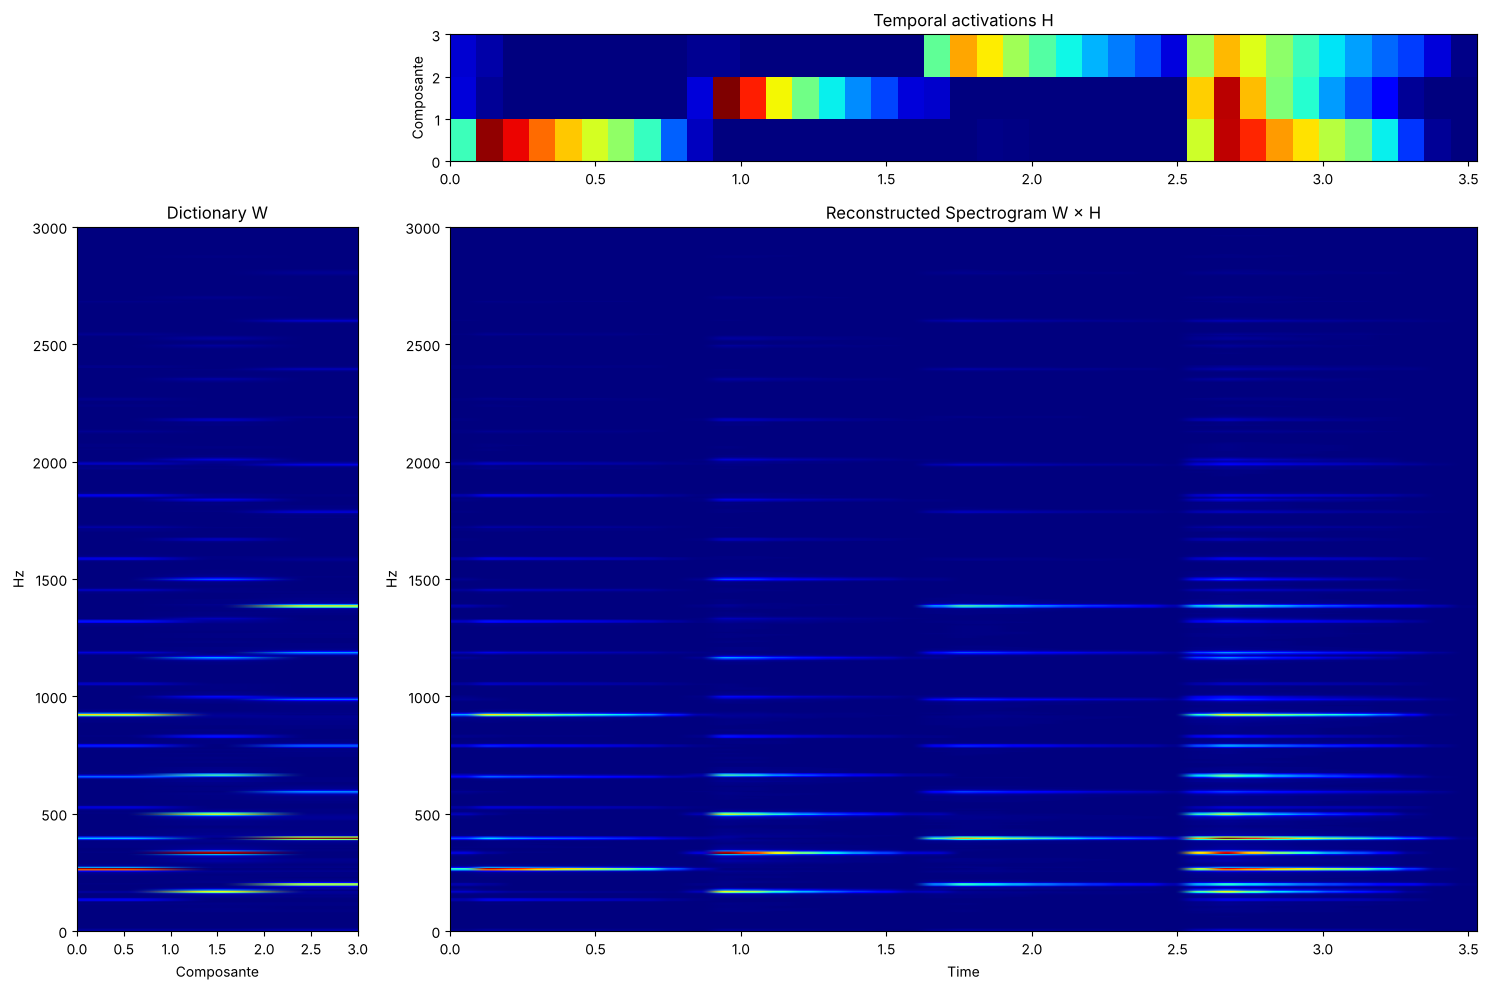

In [20]:
#Pour le piano
D_piano, A_piano = calculDA_viaNMF(M_piano, e=1e-8, nCompos=3)
afficher_NMF(D_piano, A_piano, M_piano, STFT_h_piano, t_h_piano)

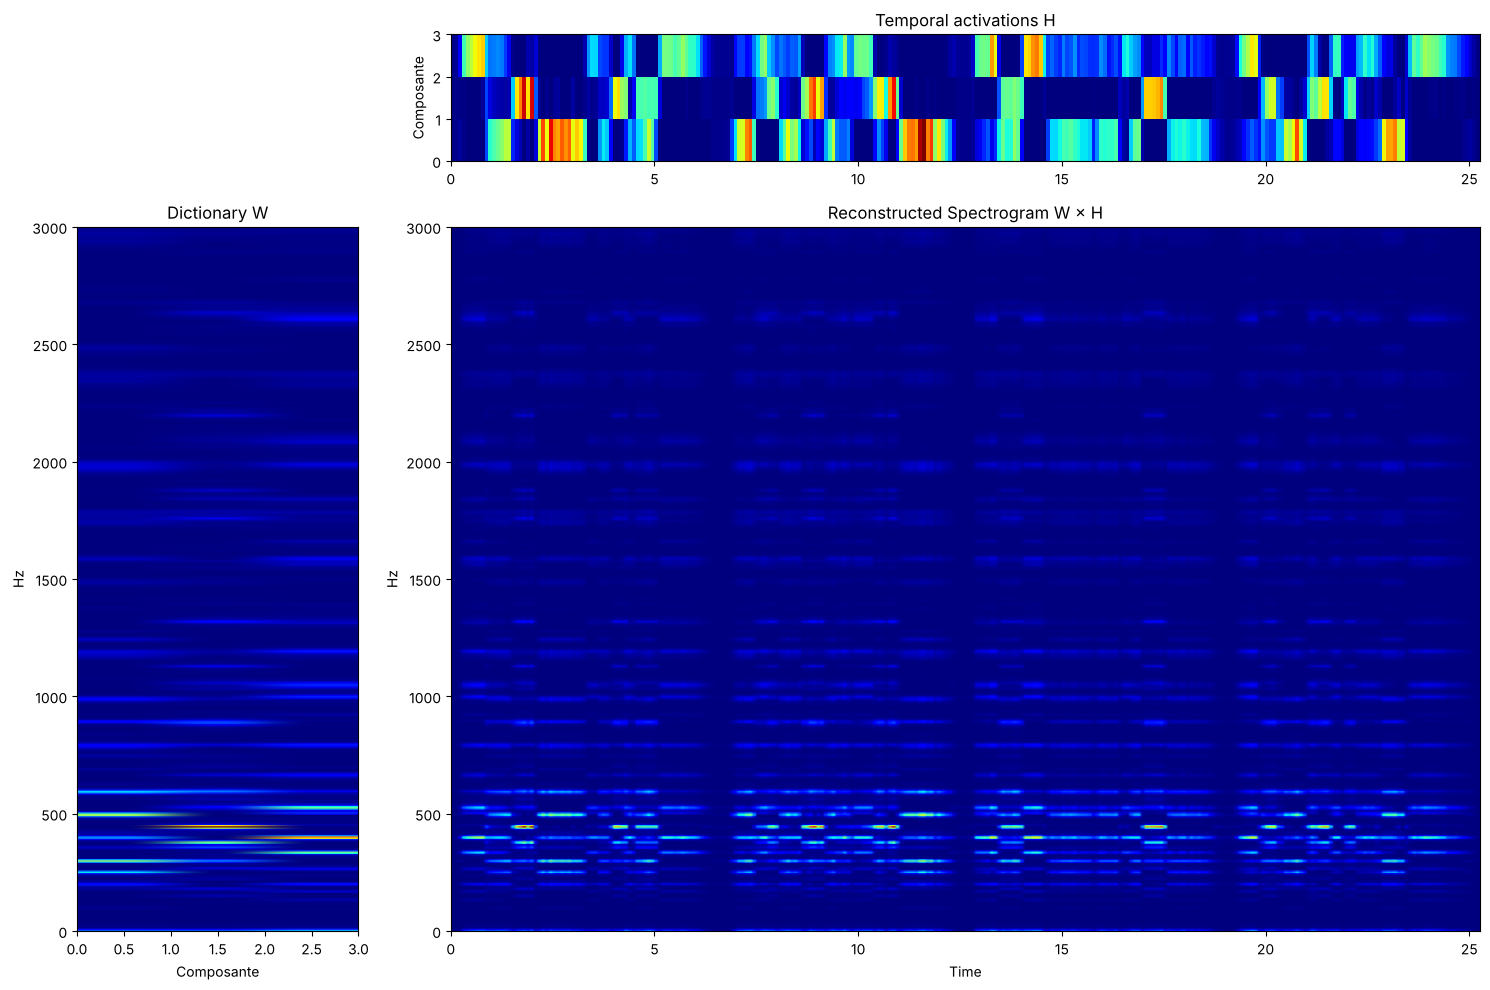

In [21]:
#Pour la musique
D_poly, A_poly = calculDA_viaNMF(M_bach, e=1e-8, nCompos=3)
afficher_NMF(D_poly, A_poly, M_bach, STFT_h_bach, t_h_bach)

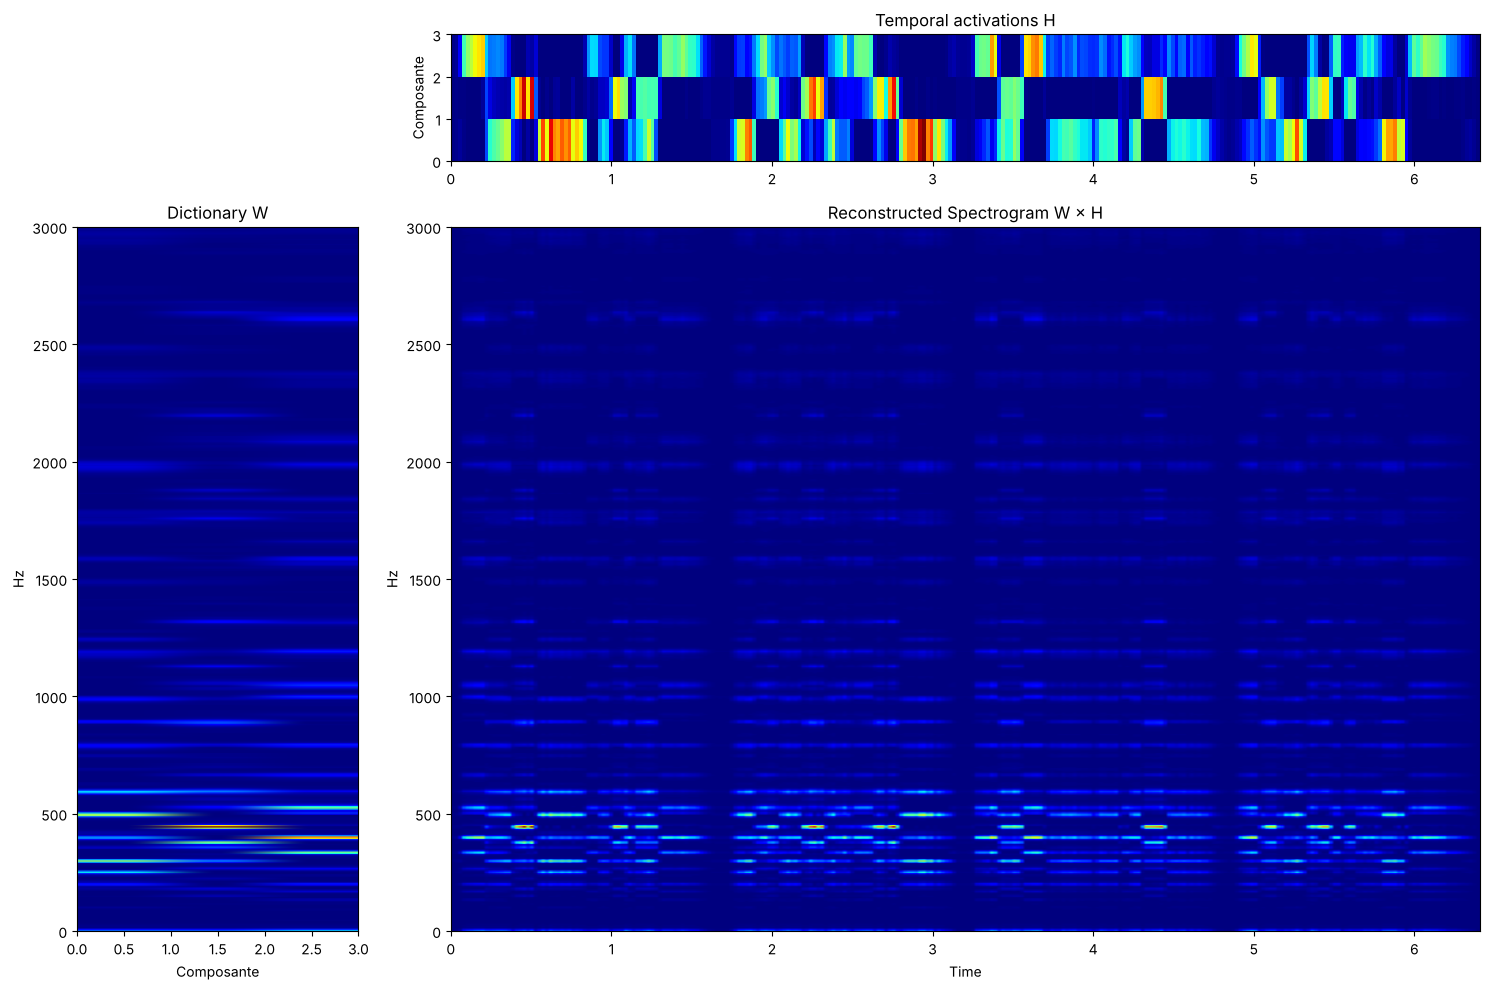

In [22]:
#Pour la musique
D_anim, A_anim = calculDA_viaNMF(M_anim, e=1e-8, nCompos=3)
afficher_NMF(D_poly, A_poly, M_anim, STFT_h_anim, t_h_anim)

In [23]:
def tracer_signaux(signaux, fs):
    plt.figure(figsize=(14, 8))

    nb = len(signaux)
    # Boucle sur chaque signal reconstruit
    for i, sig in enumerate(signaux):
        # Création de l'axe temporel associé au signal
        t = np.linspace(0, len(sig)/fs, len(sig))
        plt.subplot(nb, 1, i+1)
        plt.plot(t, sig)
        plt.title(f"Source {i}")
        plt.xlabel("Temps (s)")
        plt.ylabel("Amplitude")

    plt.tight_layout()
    plt.show()

D’après nos besoins d’analyse, il était également nécessaire d’observer les signaux reconstruits directement dans le domaine temporel.
La fonction tracer_signaux a donc été utilisée pour afficher séparément chaque signal issu de la séparation.<br><br>
Cette représentation nous permet d’analyser la forme des signaux, leur évolution dans le temps et leur cohérence globale.
L’affichage distinct de chaque source facilite la comparaison entre les signaux obtenus.<br>
Cette étape complète l’analyse fréquentielle en apportant une validation supplémentaire de la qualité de la séparation.

[STFT] nperseg = 8192, noverlap = 4096


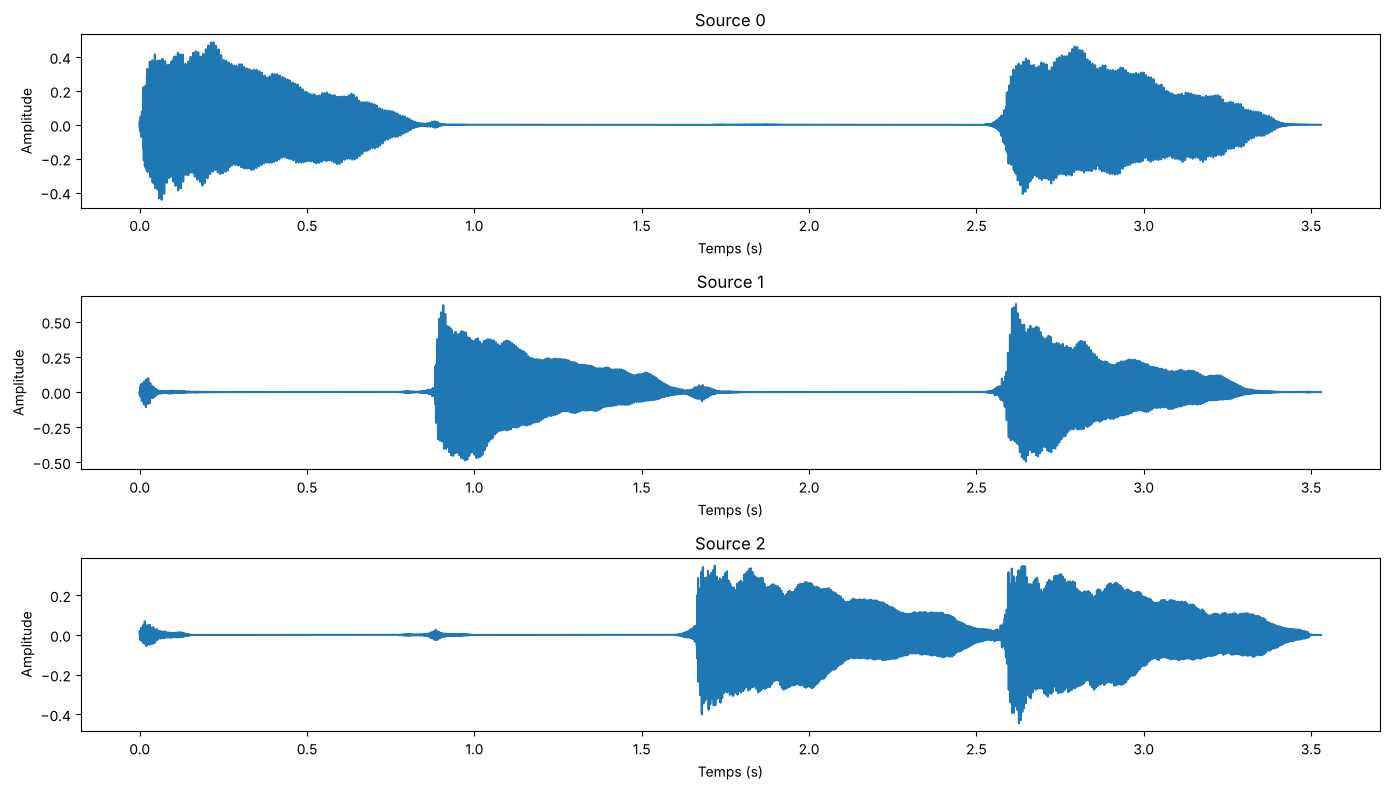

In [24]:
#Pour le piano
nps, no = calculate_stft_params(extrait_piano, freq_piano)
signaux_piano = recomposition(A_piano, D_piano,Zxx_piano, freq_piano, "hann", nps, no)
tracer_signaux(signaux_piano, freq_piano)

import IPython.display as ipd
for i in range(3):
    ipd.display(ipd.Audio(signaux_piano[i],rate=freq_piano))


[STFT] nperseg = 8192, noverlap = 4096


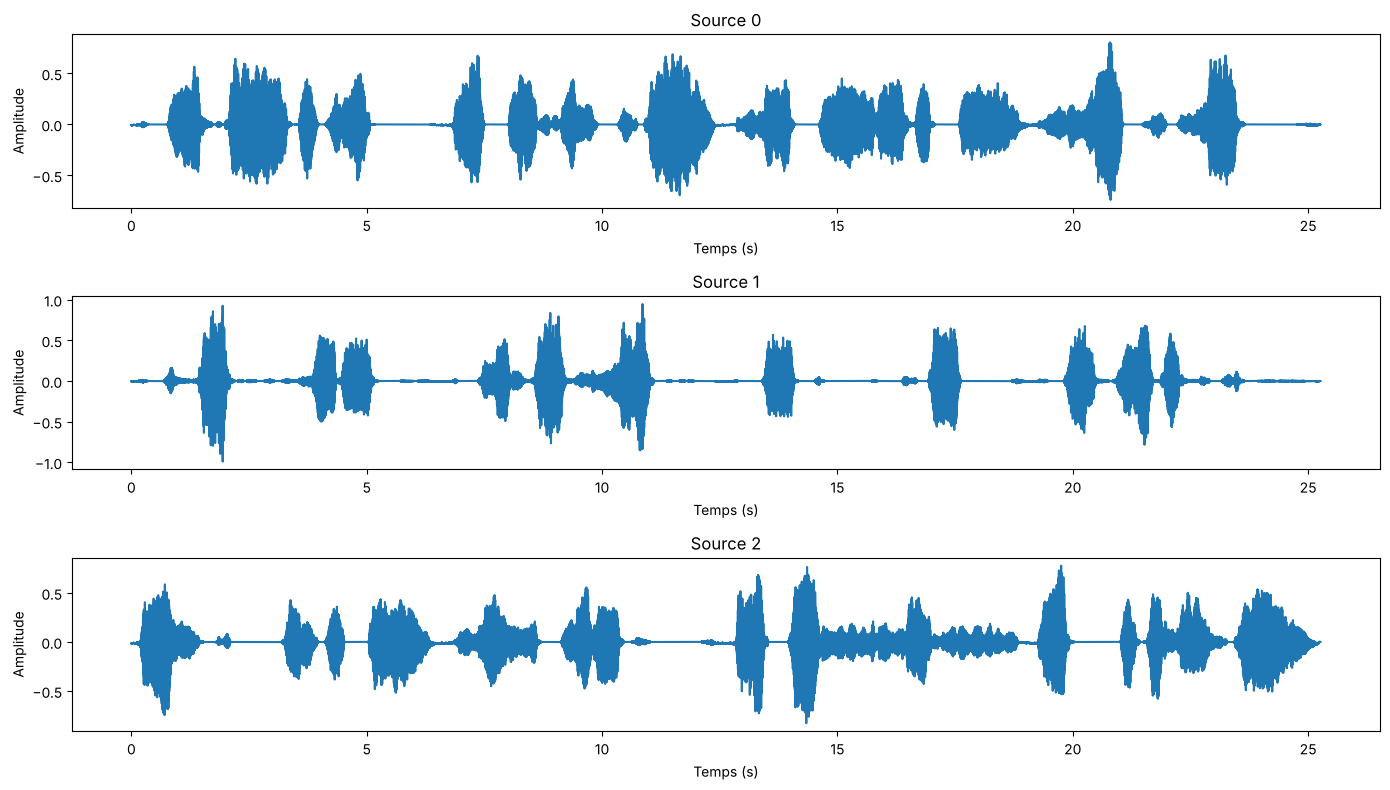

In [25]:
#Pour la musique 
nps, no = calculate_stft_params(extrait_bach, freq_bach)
signaux_poly = recomposition(A_poly, D_poly, Zxx_bach, freq_bach, "hann", nps, no)
tracer_signaux(signaux_poly, freq_bach)

import IPython.display as ipd
for i in range(3):
    ipd.display(ipd.Audio(signaux_poly[i],rate=freq_bach))

[STFT] nperseg = 8192, noverlap = 4096


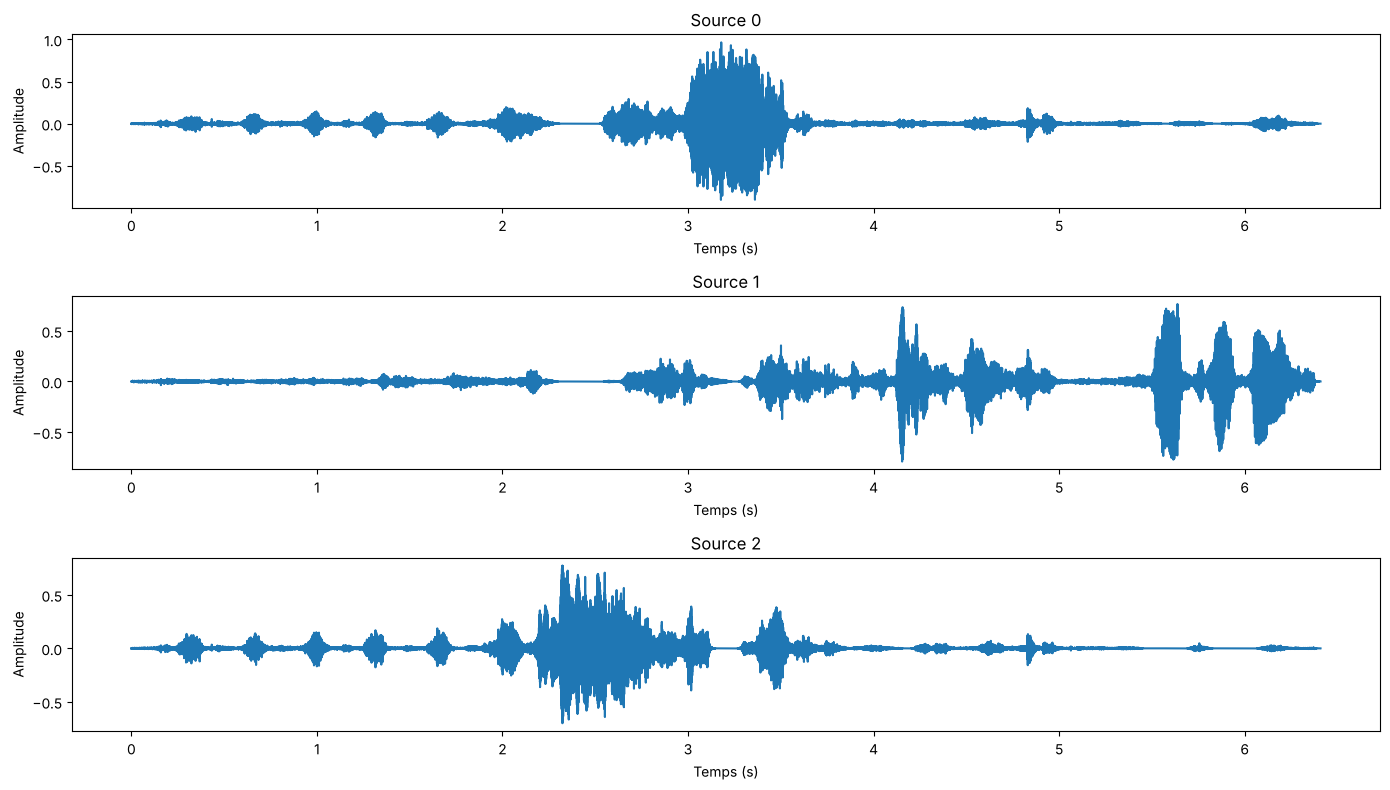

In [26]:
#Pour les animaux
nps, no = calculate_stft_params(extrait_anim, freq_anim)
signaux_anim = recomposition(A_anim, D_anim, Zxx_anim, freq_anim, "hann", nps, no)
tracer_signaux(signaux_anim, freq_anim)

import IPython.display as ipd
for i in range(3):
    ipd.display(ipd.Audio(signaux_anim[i],rate=freq_anim))

# IV - Perspectives d'Améliorations

Dans cette dernière sous-partie, nous allons explorer les perspectives d’amélioration de ce projet. En effet, nous avons appris à décomposer un signal à l’aide de différents outils, mais la question se pose de savoir comment réaliser cette décomposition de manière plus optimale afin d’obtenir de meilleurs résultats. C’est ce que nous allons étudier dans la suite.

### 4.1 Trouver la meilleure fenêtre pour la STFT

Dans le cadre de notre projet, nous avons étudié deux types de fenêtres pour la STFT : la fenêtre de Hann et la fenêtre gaussienne. Nous pensions initialement qu’il suffisait de choisir une fenêtre qui fonctionne correctement. Cependant, il nous a été suggéré d’explorer les différentes fenêtres disponibles ainsi que leurs différences. Nous nous sommes donc penchés sur ce sujet et avons mené des recherches afin de mieux comprendre l’influence du choix de la fenêtre sur les résultats obtenus.

##### 4.1.1 Les différentes fenêtres

Plusieurs types de fenêtres peuvent être utilisés lors de la stft, chacun présentant des compromis différents entre la résolution temporelle et la résolution fréquentielle. 

Par exemple, la fenêtre de Hann est largement utilisée car elle réduit efficacement les effets de fuite spectrale tout en offrant de bons résultats globaux. 

La fenêtre de Hamming est proche de la fenêtre de Hann, avec une atténuation légèrement différente des lobes secondaires. 

La fenêtre gaussienne, quant à elle, permet un bon équilibre temps–fréquence, mais son comportement dépend du paramètre choisi, ce qui peut compliquer son utilisation.

D’autres fenêtres, comme la fenêtre rectangulaire, offrent une bonne résolution temporelle mais génèrent davantage de fuite spectrale. 

Cependant, dans le cadre de ce projet et pour les signaux analysés, les différences entre ces fenêtres restent négligeables. Comme le montre l’image ci-dessous, les formes des fenêtres sont légèrement différentes, mais elles restent globalement proches. Cela montre que le choix de la fenêtre n’a qu’un impact modéré sur la décomposition du signal et sur les résultats finaux dans notre cas d’étude.

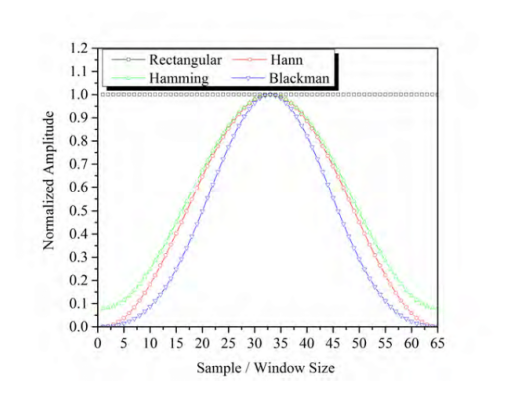

In [27]:
img = mpimg.imread('../data/Fenetres.png')

plt.figure(figsize=(10,5)) 
plt.imshow(img)
plt.axis('off')
plt.show()

##### 4.1.2 Applications et comparaison des fenêtres

Nous allons donc appliquer différentes fenêtres sur notre signal de piano et comparer les résultats obtenus afin d’illustrer nos propos.

In [28]:
# On reprend notre fonction STFT en ajoutant un paramètre en entrée pour la fenêtre
def STFT_fenetre(x,f,fenetre):
    # Normalisation
    x = x.astype(float)
    x /= np.max(np.abs(x))

    # Paramètres de STFT et calcul de la stft
    taille,overlap=calculate_stft_params(x,f)
    freq, t, Zxx = sc.signal.stft(x,fs=f,nperseg=taille,noverlap=overlap,window=fenetre)

    #Valeur absolue
    S = np.abs(Zxx)

    # Passage en dB
    S_db = 20 * np.log10(S + 1e-12)

    return t, freq, S_db

# On l'applique avec Hamming, Blackman et Rectangular ( boxcar sur scipy )
t_hamming, freq_hamming, S_hamming = STFT_fenetre(extrait_piano,freq_piano,'hamming')
t_blackman, freq_blackman, S_blackman = STFT_fenetre(extrait_piano,freq_piano,'blackman')
t_rect, freq_rect, S_rect = STFT_fenetre(extrait_piano,freq_piano,'boxcar')

[STFT] nperseg = 8192, noverlap = 4096
[STFT] nperseg = 8192, noverlap = 4096
[STFT] nperseg = 8192, noverlap = 4096


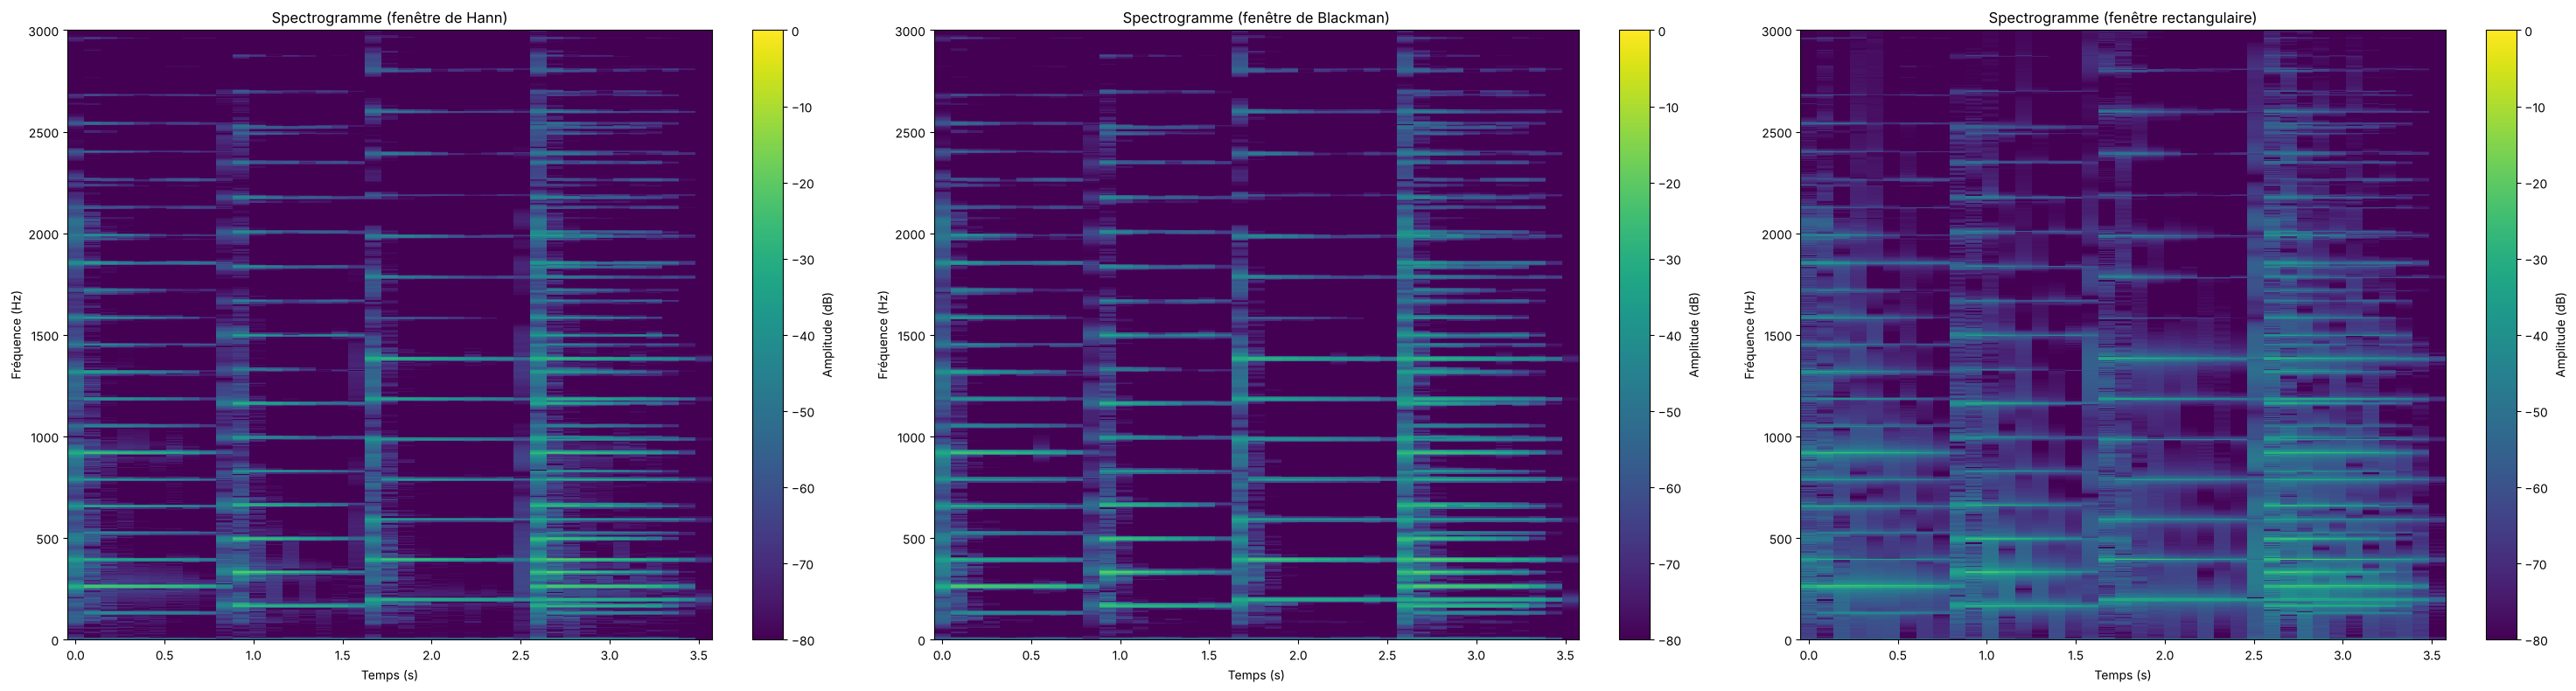

In [29]:
#Puis on affiche 
plt.figure(figsize=(30, 8))
plt.subplot(1, 3, 1)
plt.pcolormesh(t_hamming, freq_hamming, S_hamming, shading='auto', cmap='viridis')
plt.ylim(0, 3000)
plt.clim(-80, 0)
plt.xlabel("Temps (s)")
plt.ylabel("Fréquence (Hz)")
plt.title("Spectrogramme (fenêtre de Hann)")
cbar1 = plt.colorbar()
cbar1.set_label("Amplitude (dB)")

plt.subplot(1, 3, 2)
plt.pcolormesh(t_blackman, freq_blackman, S_blackman, shading='auto', cmap='viridis')
plt.ylim(0, 3000)
plt.clim(-80, 0)
plt.xlabel("Temps (s)")
plt.ylabel("Fréquence (Hz)")
plt.title("Spectrogramme (fenêtre de Blackman)")
cbar2 = plt.colorbar()
cbar2.set_label("Amplitude (dB)")

plt.subplot(1, 3, 3)
plt.pcolormesh(t_rect, freq_rect, S_rect, shading='auto', cmap='viridis')
plt.ylim(0, 3000)
plt.clim(-80, 0)
plt.xlabel("Temps (s)")
plt.ylabel("Fréquence (Hz)")
plt.title("Spectrogramme (fenêtre rectangulaire)")
cbar3 = plt.colorbar()
cbar3.set_label("Amplitude (dB)")

plt.tight_layout()
plt.show()

Finalement, ces tests montrent que les différences entre les fenêtres restent minimes dans le cadre de notre projet, surtout si l’on compare les spectrogrammes obtenus avec les fenêtres de Hann et gaussienne présentés précédemment. Les spectrogrammes sont globalement similaires, et les variations observées sont peu significatives (peut-être un peu plus avec la fenêtre rectangulaire, qui apparaît plus floue). Cela confirme quand même que, pour les signaux analysés, le choix de la fenêtre n’a qu’un impact modéré sur la décomposition du signal et sur les résultats finaux.

### 4.2 Trouver le nombre de composantes optimales
Cherchons maintenant à trouver le nombre de composants optimaux.
Pour utiliser les fonctions de décomposition NMF, il est nécessaire de fournir en entrée le nombre de composantes, à extraire. Cependant, après recherche, nous n'avons trouvé aucune règle générale pour le déterminer automatiquement.  

Dans un cas simple, comme pour le piano, il est possible de choisir le nombre de composantes à l'oreille, mais pour un son composé de plusieurs notes et instruments, cette approche devient rapidement impraticable. Nous avons donc décidé d'adopter deux méthodes pour estimer le nombre optimal de composantes.

#### 4.2.1 Méthode du BIC
La première méthode, conseillé par le chargé de TD, est basée sur le critère d'information bayésien (BIC). Le BIC est une mesure statistique qui évalue la qualité d'un modèle en tenant compte à la fois de son ajustement aux données et de sa complexité. Il pénalise les modèles trop complexes et utilise ainsi la complexité et l'erreur. 

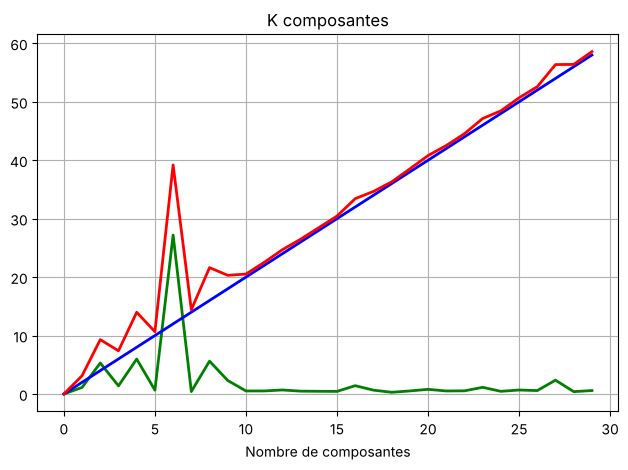

In [30]:
# Fonction pour trouver le nombre optimal de composantes avec la méthode du BIC
def trouver_nComposBIC(M,kmax=30):
    p = np.zeros(kmax)
    bic = np.zeros(kmax)
    erreur = np.zeros(kmax)
    alpha=2
    for k in range(1,kmax):
        D, A,_,_ = calculDA_viaItakuraSaito(M, nCompos=k, eps=1e-8, max_iter=250)
        erreur[k] = np.linalg.norm(M-np.matmul(D,A))
        p[k]=k*alpha
        bic[k]=erreur[k]+p[k]
    return erreur, p, bic

#On l'applique sur le piano
e_bic_piano, p_bic_piano, bic_piano = trouver_nComposBIC(M_piano)

#On affiche les résultats
plt.plot(range(30), e_bic_piano, color='green', linewidth=2)
plt.plot(range(30), p_bic_piano, color='blue', linewidth=2)
plt.plot(range(30), bic_piano, color='red', linewidth=2)
plt.title('K composantes')
plt.xlabel('Nombre de composantes')
plt.grid()
plt.tight_layout()
plt.show()

Le principal inconvénient de cette méthode réside dans le choix délicat du paramètre alpha, pour lequel aucune règle précise n'existe, et qui doit être déterminé par tâtonnements, ce qui reste incertain.  

#### 4.2.2 Méthode du coude 
La seconde méthode, consiste à calculer l'erreur de reconstruction pour différents nombres de composantes et à comparer les résultats (méthode du coude utilisé généralement en k-means).

Ici on choisit le nombre de composantes en comparant les erreurs entre-elles et en choisissant celui qui possède la plus grande diminution de l'erreur par rapport au nombre précédent.

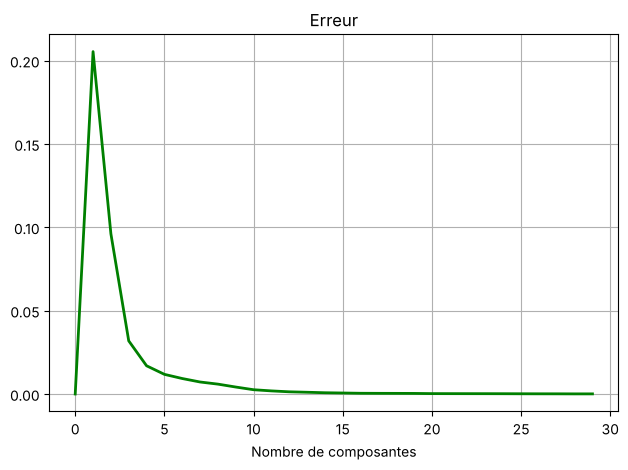

In [31]:
import warnings
from sklearn.exceptions import ConvergenceWarning
# NMF peut s'arrêter à 200 itérations avant d'atteindre la tolérance demandée :
# ce n'est pas gênant ici car on compare seulement l'évolution de l'erreur selon k
warnings.filterwarnings("ignore", category=ConvergenceWarning)

# Fonction pour trouver le nombre optimal de composantes avec la méthode du coude
def trouver_nComposCoude(M, kmax=30):
    n, m = M.shape
    p = np.zeros(kmax)
    bic = np.zeros(kmax)
    erreur = np.zeros(kmax)
    for k in range(1,kmax):
        D, A = calculDA_viaNMF(M, e=1e-8, nCompos=k)
        erreur[k] = np.linalg.norm(M-np.matmul(D,A),'fro')**2
    drops = erreur[1:kmax-2] - erreur[3:kmax]
    best_k = np.argmax(drops) + 1
    best_k_plus_1 = best_k + 2
    return erreur, p, best_k_plus_1

e_coude_piano, p_coude_piano, k_coude_opt = trouver_nComposCoude(M_piano)

plt.plot(range(30), e_coude_piano, color='green', linewidth=2)
plt.title('Erreur')
plt.xlabel('Nombre de composantes')
plt.grid()
plt.tight_layout()
plt.show()

Cette méthode semble être satisfaisante pour estimer le nombre de composantes optimales dans notre cas. Pour le piano par exemple, elle suggère un nombre optimal de 3 composantes, ce qui correspond bien aux trois notes jouées dans l'extrait audio. Nous en avons donc conclu que la méthode du coude constitue l'approche la plus fiable pour déterminer le nombre optimal de composantes.

# V - Conclusion

Lors de ce projet, nous avons pu mettre en pratique les notions vues en cours de traitement du signal et d’analyse numérique dans le cadre de la décomposition de signaux audio. À partir des spectrogrammes obtenus par STFT, la factorisation en matrices non négatives a permis d’extraire les matrices 𝐷 et 𝐴, représentant respectivement les bases spectrales et leurs activations temporelles. Nous avons comparé trois critères de divergence : les moindres carrés, la divergence de Kullback–Leibler et la divergence d’Itakura–Saito, chacun présentant des avantages différents pour la reconstruction des signaux.

Pour améliorer nos résultats, nous avons exploré l’influence des fenêtres utilisées pour la STFT et constaté que, dans le cadre de nos signaux, le choix de la fenêtre n’avait qu’un impact modéré. Nous avons également cherché à déterminer le nombre optimal de composants, en testant plusieurs méthodes et en retenant la méthode du coude comme la plus efficace.

Nos fonctions ont été appliquées sur différents types de signaux. Sur l’extrait de piano, les résultats se sont révélés très concluants. Pour les autres signaux, les résultats ont été un peu moins précis. Cela peut s’expliquer par plusieurs facteurs : le bruit, le mélange complexe des sons, ou encore le fait qu’il ne s’agissait pas de simples notes isolées mais de sons composites ou d’instruments multiples, ce qui rend la séparation plus difficile.

Enfin, ce projet nous a permis de travailler efficacement en équipe, d’améliorer notre organisation grâce à GitLab et d’approfondir notre compréhension des outils de séparation de sources audio.

# VII - Bibliographie

### Références pour la STFT :
Consultés pour la dernière fois le 21/12/2025
1. Documentation SciPy - Pour la fonction stft : https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.stft.html
2. Analyse temps–fréquence - Pour les formules et la compréhension de la méthode: https://moodle.insa-rouen.fr/pluginfile.php/231759/mod_resource/content/1/cours10-ondelettes_perrier_short.pdf
3. Décomposition de spectrogrammes musicaux informée par des modèles de synthèse spectrale - Pour la compréhension de la méthode et du sujet et le choix de la fenêtre: https://pastel.hal.science/pastel-00648997/file/these.pdf
4. Vidéo Digital Music Module 11: Short-Time Fourier Transform (STFT) Chromatic And Vibrato - Pour la réalisation de la fonction stft à la main https://www.youtube.com/watch?v=65EYg6enKFs
5. Fenêtres de Hann - Pour mettre en entrée une fenêtre de Hann dans la stft à la main : https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.windows.hann.html

### Références pour la NMF :
Consultés pour la dernière fois le 21/12/2025
1. Méthode des Moindres-Carrés Analytique - Pour les calculs de Trace(...) : https://www.math.uwaterloo.ca/~hwolkowi/matrixcookbook.pdf
2. Méthode de KL Divergence - Pour la formule et le principe : https://www.datacamp.com/fr/tutorial/kl-divergence
3. Méthode de Itakura-Saito - Pour la formule : https://gretsi.fr/data/peyresq/2013/cours-7.2.pdf
4. Méthode du coude - Pour la compréhension de la méthode : https://en.wikipedia.org/wiki/Determining_the_number_of_clusters_in_a_data_set#Elbow_method
5. Méthode du BIC - Pour la compréhension de la méthode : https://fr.wikipedia.org/wiki/Crit%C3%A8re_d%27information_bay%C3%A9sien

### Références pour la Reconstruction:
Consultés pour la dernière fois le 21/12/2025
1. https://vincmazet.github.io/signal1/fourier/temps-frequence.html
2. Reconstruction temps–fréquence (STFT / ISTFT) : https://vincmazet.github.io/signal1/fourier/temps-frequence.html
3. Masquage spectral et séparation de sources audio : https://www.cs.tut.fi/~tuomasv/publications/Virtanen_TASLP_2007.pdf
4. Reconstruction avec conservation de la phase (ISTFT) : https://ieeexplore.ieee.org/document/1164317


### Références pour Perspectives d'amélioration : 
Consultés pour la dernière fois le 21/12/2025
1. L'image d'illustration qui compare les fenêtres : https://www.researchgate.net/figure/General-cosine-windowing-methods-Rectangular-Hann-Hamming-and-Blackman-window-of_fig40_295417670
2. Comparaison des fenêtres et de leur utilisation : https://fr.wikipedia.org/wiki/Fen%C3%AAtrage et https://en.wikipedia.org/wiki/Window_function
3. Choix de la fenêtre : https://fr.mathworks.com/matlabcentral/answers/503960-choosing-window-for-stft-function et https://stackoverflow.com/questions/27703047/how-to-choose-a-valid-window-of-the-signal-in-stft

